In [1]:
import os
import numpy as np
from datetime import datetime
import tf2onnx
import keras
from keras.metrics import BinaryAccuracy, SparseCategoricalAccuracy
from keras.models import load_model
from tqdm import tqdm  # For dynamic progress updates
from cnn.model import ResNetClassifier
from utils import load_features_from_hdf5
from data_preprocessing import (
    extract_and_concatenate_with_grouping,
    extract_and_concatenate_with_grouping_channel,
    extract_and_concatenate_with_grouping_tdl_cdl,
    extract_and_concatenate_with_grouping_channel_tdl_cdl,
    extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate,
    extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate
)

from cnn.layers import (
    downsample,
    upsample,
    integrate_oper_upsample,
    integrate_oper_downsample,
    EncoderMiniBlock,
    DecoderMiniBlock,
    Oper2D,
    Oper2DTranspose,
)
from cnn.model import ResNetClassifier
from cnn.module import ResNet
from evaluation import print_metrics, print_metrics_multiclass
from visualization import (
    plot_confusion_matrix,
    plot_confusion_matrix_multiclass,
    plot_roc_curve,
    plot_roc_curve_multiclass,
)
import onnxruntime as ort  # ONNX Runtime for inference
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0  # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    print(f"Using GPU {gpu_num}")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel("ERROR")

2025-07-05 09:51:39.597565: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751698299.617715 3326678 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751698299.623781 3326678 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1751698299.639329 3326678 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751698299.639352 3326678 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751698299.639355 3326678 computation_placer.cc:177] computation placer alr

Using GPU 0


In [3]:
# Load features from HDF5 files

# mimo_los_test = load_features_from_hdf5('data/dataset_sionna_mimo_los_test.h5')
# mimo_los_train = load_features_from_hdf5('data/dataset_sionna_mimo_los.h5')
# mimo_nlos_test = load_features_from_hdf5('data/dataset_sionna_mimo_nlos_test.h5')
# mimo_nlos_train = load_features_from_hdf5('data/dataset_sionna_mimo_nlos.h5')
mimo_los_test = load_features_from_hdf5('dataset_sionna_mimo_los_test_user0.h5')
mimo_los_train = load_features_from_hdf5('data/dataset_sionna_mimo_los.h5')
mimo_nlos_test = load_features_from_hdf5('dataset_sionna_mimo_nlos_test_user0.h5')
mimo_nlos_train = load_features_from_hdf5('data/dataset_sionna_mimo_nlos.h5')

siso_los_test = load_features_from_hdf5('data/dataset_sionna_siso_los_test.h5')
siso_los_train = load_features_from_hdf5('data/dataset_sionna_siso_los.h5')
siso_nlos_test = load_features_from_hdf5('data/dataset_sionna_siso_nlos_test.h5')
siso_nlos_train = load_features_from_hdf5('data/dataset_sionna_siso_nlos.h5')

# tdl_cdl_test = load_features_from_hdf5('data/dataset_tdl_cdl_test.h5')
# tdl_cdl_train = load_features_from_hdf5('data/dataset_tdl_cdl.h5')
tdl_cdl_test = load_features_from_hdf5('dataset/dataset_tdl_cdl_test.h5')
tdl_cdl_train = load_features_from_hdf5('dataset/dataset_tdl_cdl.h5')


tdl_cdl_train_siso = load_features_from_hdf5('data/dataset_tdl_cdl_siso.h5')
tdl_cdl_test_siso = load_features_from_hdf5('data/dataset_tdl_cdl_test_siso.h5')
tdl_cdl_train_mimo = load_features_from_hdf5('data/dataset_tdl_cdl_mimo.h5')
tdl_cdl_test_mimo = load_features_from_hdf5('data/dataset_tdl_cdl_test_mimo.h5')

tdl_cdl_0db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_0db_siso.h5')
tdl_cdl_5db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_5db_siso.h5')
tdl_cdl_10db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_10db_siso.h5')
tdl_cdl_15db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_15db_siso.h5')
tdl_cdl_0db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_0db_mimo.h5')
tdl_cdl_5db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_5db_mimo.h5')
tdl_cdl_10db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_10db_mimo.h5')
tdl_cdl_15db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_15db_mimo.h5')

# Extract and concatenate for MIMO datasets
train_mimo_los, train_mimo_los_labels = extract_and_concatenate_with_grouping(mimo_los_train)
train_mimo_nlos, train_mimo_nlos_labels = extract_and_concatenate_with_grouping(mimo_nlos_train)
train_siso_los, train_siso_los_labels = extract_and_concatenate_with_grouping(siso_los_train)
train_siso_nlos, train_siso_nlos_labels = extract_and_concatenate_with_grouping(siso_nlos_train)

train_siso_los_without_duplicate, train_siso_los_labels_without_duplicate = extract_and_concatenate_with_grouping(siso_los_train, without_duplicate=True)
train_siso_nlos_without_duplicate, train_siso_nlos_labels_without_duplicate = extract_and_concatenate_with_grouping(siso_nlos_train, without_duplicate=True)

test_mimo_los, test_mimo_los_labels = extract_and_concatenate_with_grouping(mimo_los_test)
test_mimo_nlos, test_mimo_nlos_labels = extract_and_concatenate_with_grouping(mimo_nlos_test)
test_siso_los, test_siso_los_labels = extract_and_concatenate_with_grouping(siso_los_test)
test_siso_nlos, test_siso_nlos_labels = extract_and_concatenate_with_grouping(siso_nlos_test)
train_tdls, train_cdls, train_tdls_labels, train_cdls_labels = extract_and_concatenate_with_grouping_tdl_cdl(tdl_cdl_train)
test_tdls, test_cdls, test_tdls_labels, test_cdls_labels = extract_and_concatenate_with_grouping_tdl_cdl(tdl_cdl_test)

train_tdls_siso, train_cdls_siso, train_tdls_labels_siso, train_cdls_labels_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_train_siso)
test_tdls_siso, test_cdls_siso, test_tdls_labels_siso, test_cdls_labels_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_test_siso)
train_tdls_mimo, train_cdls_mimo, train_tdls_labels_mimo, train_cdls_labels_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_train_mimo)
test_tdls_mimo, test_cdls_mimo, test_tdls_labels_mimo, test_cdls_labels_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_test_mimo)

test_tdls_0db_siso, test_cdls_0db_siso, test_tdls_labels_0db_siso, test_cdls_labels_0db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_0db_siso_test)
test_tdls_5db_siso, test_cdls_5db_siso, test_tdls_labels_5db_siso, test_cdls_labels_5db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_5db_siso_test)
test_tdls_10db_siso, test_cdls_10db_siso, test_tdls_labels_10db_siso, test_cdls_labels_10db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_10db_siso_test)
test_tdls_15db_siso, test_cdls_15db_siso, test_tdls_labels_15db_siso, test_cdls_labels_15db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_15db_siso_test)
test_tdls_0db_mimo, test_cdls_0db_mimo, test_tdls_labels_0db_mimo, test_cdls_labels_0db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_0db_mimo_test)
test_tdls_5db_mimo, test_cdls_5db_mimo, test_tdls_labels_5db_mimo, test_cdls_labels_5db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_5db_mimo_test)
test_tdls_10db_mimo, test_cdls_10db_mimo, test_tdls_labels_10db_mimo, test_cdls_labels_10db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_10db_mimo_test)
test_tdls_15db_mimo, test_cdls_15db_mimo, test_tdls_labels_15db_mimo, test_cdls_labels_15db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_15db_mimo_test)

train_mimo_los_channel, train_mimo_los_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_los_train)
train_mimo_nlos_channel, train_mimo_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_nlos_train)
train_siso_los_channel, train_siso_los_labels_channel = extract_and_concatenate_with_grouping_channel(siso_los_train)
train_siso_nlos_channel, train_siso_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(siso_nlos_train)

train_siso_los_channel_without_duplicate, train_siso_los_labels_channel_without_duplicate = extract_and_concatenate_with_grouping_channel(siso_los_train, without_duplicate=True)
train_siso_nlos_channel_without_duplicate, train_siso_nlos_labels_channel_without_duplicate = extract_and_concatenate_with_grouping_channel(siso_nlos_train, without_duplicate=True)
test_mimo_los_channel, test_mimo_los_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_los_test)
test_mimo_nlos_channel, test_mimo_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_nlos_test)
test_siso_los_channel, test_siso_los_labels_channel = extract_and_concatenate_with_grouping_channel(siso_los_test)
test_siso_nlos_channel, test_siso_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(siso_nlos_test)


# Extract and concatenate for MIMO datasets with channel dimension
train_tdls_channel, train_cdls_channel, label_tdls_channel, label_cdls_channel = extract_and_concatenate_with_grouping_channel_tdl_cdl(tdl_cdl_train)
test_tdls_channel, test_cdls_channel, test_label_tdls_channel, test_label_cdls_channel = extract_and_concatenate_with_grouping_channel_tdl_cdl(tdl_cdl_test)

train_tdls_channel_siso, train_cdls_channel_siso, label_tdls_channel_siso, label_cdls_channel_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_train_siso)
test_tdls_channel_siso, test_cdls_channel_siso, test_label_tdls_channel_siso, test_label_cdls_channel_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_test_siso)
train_tdls_channel_mimo, train_cdls_channel_mimo, label_tdls_channel_mimo, label_cdls_channel_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_train_mimo)
test_tdls_channel_mimo, test_cdls_channel_mimo, test_label_tdls_channel_mimo, test_label_cdls_channel_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_test_mimo)

test_tdls_channel_0db_siso, test_cdls_channel_0db_siso, test_label_tdl_channel_0db_siso, test_label_cdl_channel_0db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_0db_siso_test)
test_tdls_channel_5db_siso, test_cdls_channel_5db_siso, test_label_tdl_channel_5db_siso, test_label_cdl_channel_5db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_5db_siso_test)
test_tdls_channel_10db_siso, test_cdls_channel_10db_siso, test_label_tdl_channel_10db_siso, test_label_cdl_channel_10db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_10db_siso_test)
test_tdls_channel_15db_siso, test_cdls_channel_15db_siso, test_label_tdl_channel_15db_siso, test_label_cdl_channel_15db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_15db_siso_test)
test_tdls_channel_0db_mimo, test_cdls_channel_0db_mimo, test_label_tdl_channel_0db_mimo, test_label_cdl_channel_0db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_0db_mimo_test)
test_tdls_channel_5db_mimo, test_cdls_channel_5db_mimo, test_label_tdl_channel_5db_mimo, test_label_cdl_channel_5db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_5db_mimo_test)
test_tdls_channel_10db_mimo, test_cdls_channel_10db_mimo, test_label_tdl_channel_10db_mimo, test_label_cdl_channel_10db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_10db_mimo_test)
test_tdls_channel_15db_mimo, test_cdls_channel_15db_mimo, test_label_tdl_channel_15db_mimo, test_label_cdl_channel_15db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_15db_mimo_test)

In [4]:
print("train_tdls shape:", train_tdls.shape)
print("train_cdls shape:", train_cdls.shape)
print("train_tdls_channel shape:", train_tdls_channel.shape)
print("train_cdls_channel shape:", train_cdls_channel.shape)
print("train_tdls_labels shape:", train_tdls_labels.shape)
print("train_cdls_labels shape:", train_cdls_labels.shape)
print("test_tdls shape:", test_tdls.shape)
print("test_cdls shape:", test_cdls.shape)
print("test_tdls_channel shape:", test_tdls_channel.shape)
print("test_cdls_channel shape:", test_cdls_channel.shape)
print("test_tdls_labels shape:", test_tdls_labels.shape)
print("test_cdls_labels shape:", test_cdls_labels.shape)
print("train_tdls_labels_siso shape:", train_tdls_labels_siso.shape)
print("train_cdls_labels_siso shape:", train_cdls_labels_siso.shape)
print("train_tdls_labels_mimo shape:", train_tdls_labels_mimo.shape)
print("train_cdls_labels_mimo shape:", train_cdls_labels_mimo.shape)
print("test_tdls_labels_siso shape:", test_tdls_labels_siso.shape)
print("test_cdls_labels_siso shape:", test_cdls_labels_siso.shape)
print("test_tdls_labels_mimo shape:", test_tdls_labels_mimo.shape)
print("test_cdls_labels_mimo shape:", test_cdls_labels_mimo.shape)
print("train_tdls_labels_0db_siso shape:", test_tdls_channel_0db_siso.shape)



train_tdls shape: (10000, 1, 1, 4, 14, 192)
train_cdls shape: (10000, 1, 1, 4, 14, 192)
train_tdls_channel shape: (10000, 1, 1, 4, 14, 192)
train_cdls_channel shape: (10000, 1, 1, 4, 14, 192)
train_tdls_labels shape: (10000,)
train_cdls_labels shape: (10000,)
test_tdls shape: (5000, 1, 1, 4, 14, 192)
test_cdls shape: (5000, 1, 1, 4, 14, 192)
test_tdls_channel shape: (5000, 1, 1, 4, 14, 192)
test_cdls_channel shape: (5000, 1, 1, 4, 14, 192)
test_tdls_labels shape: (5000,)
test_cdls_labels shape: (5000,)
train_tdls_labels_siso shape: (10000,)
train_cdls_labels_siso shape: (10000,)
train_tdls_labels_mimo shape: (10000,)
train_cdls_labels_mimo shape: (10000,)
test_tdls_labels_siso shape: (5000,)
test_cdls_labels_siso shape: (5000,)
test_tdls_labels_mimo shape: (5000,)
test_cdls_labels_mimo shape: (5000,)
train_tdls_labels_0db_siso shape: (5000, 1, 1, 2, 14, 192)


In [5]:
# Combine dimensions for MIMO data (e.g., 1 and 2 -> 1 * 2 = 2)
train_mimo_los = train_mimo_los.reshape(train_mimo_los.shape[0], train_mimo_los.shape[1], train_mimo_los.shape[2] * train_mimo_los.shape[3], train_mimo_los.shape[4], train_mimo_los.shape[5])
train_mimo_nlos = train_mimo_nlos.reshape(train_mimo_nlos.shape[0], train_mimo_nlos.shape[1], train_mimo_nlos.shape[2] * train_mimo_nlos.shape[3], train_mimo_nlos.shape[4], train_mimo_nlos.shape[5])
test_mimo_los = test_mimo_los.reshape(test_mimo_los.shape[0], test_mimo_los.shape[1], test_mimo_los.shape[2] * test_mimo_los.shape[3], test_mimo_los.shape[4], test_mimo_los.shape[5])
test_mimo_nlos = test_mimo_nlos.reshape(test_mimo_nlos.shape[0], test_mimo_nlos.shape[1], test_mimo_nlos.shape[2] * test_mimo_nlos.shape[3], test_mimo_nlos.shape[4], test_mimo_nlos.shape[5])
print("train_mimo_los shape after reshape:", train_mimo_los.shape)
print("train_mimo_nlos shape after reshape:", train_mimo_nlos.shape)
print("test_mimo_los shape after reshape:", test_mimo_los.shape)
print("test_mimo_nlos shape after reshape:", test_mimo_nlos.shape)

train_mimo_los_channel = train_mimo_los_channel.reshape(train_mimo_los_channel.shape[0], train_mimo_los_channel.shape[1], train_mimo_los_channel.shape[2] * train_mimo_los_channel.shape[3], train_mimo_los_channel.shape[4], train_mimo_los_channel.shape[5])
train_mimo_nlos_channel = train_mimo_nlos_channel.reshape(train_mimo_nlos_channel.shape[0], train_mimo_nlos_channel.shape[1], train_mimo_nlos_channel.shape[2] * train_mimo_nlos_channel.shape[3], train_mimo_nlos_channel.shape[4], train_mimo_nlos_channel.shape[5])
test_mimo_los_channel = test_mimo_los_channel.reshape(test_mimo_los_channel.shape[0], test_mimo_los_channel.shape[1], test_mimo_los_channel.shape[2] * test_mimo_los_channel.shape[3], test_mimo_los_channel.shape[4], test_mimo_los_channel.shape[5])
test_mimo_nlos_channel = test_mimo_nlos_channel.reshape(test_mimo_nlos_channel.shape[0], test_mimo_nlos_channel.shape[1], test_mimo_nlos_channel.shape[2] * test_mimo_nlos_channel.shape[3], test_mimo_nlos_channel.shape[4], test_mimo_nlos_channel.shape[5])
print("train_mimo_los_channel shape after reshape:", train_mimo_los_channel.shape)
print("train_mimo_nlos_channel shape after reshape:", train_mimo_nlos_channel.shape)
print("test_mimo_los_channel shape after reshape:", test_mimo_los_channel.shape)
print("test_mimo_nlos_channel shape after reshape:", test_mimo_nlos_channel.shape)

# Combine dimensions for SISO data (e.g., 1 and 2 -> 1 * 2 = 2)
train_siso_los = train_siso_los.reshape(train_siso_los.shape[0], train_siso_los.shape[1], train_siso_los.shape[2] * train_siso_los.shape[3], train_siso_los.shape[4], train_siso_los.shape[5])
train_siso_nlos = train_siso_nlos.reshape(train_siso_nlos.shape[0], train_siso_nlos.shape[1], train_siso_nlos.shape[2] * train_siso_nlos.shape[3], train_siso_nlos.shape[4], train_siso_nlos.shape[5])
test_siso_los = test_siso_los.reshape(test_siso_los.shape[0], test_siso_los.shape[1], test_siso_los.shape[2] * test_siso_los.shape[3], test_siso_los.shape[4], test_siso_los.shape[5])
test_siso_nlos = test_siso_nlos.reshape(test_siso_nlos.shape[0], test_siso_nlos.shape[1], test_siso_nlos.shape[2] * test_siso_nlos.shape[3], test_siso_nlos.shape[4], test_siso_nlos.shape[5])
print("train_siso_los shape after reshape:", train_siso_los.shape)
print("train_siso_nlos shape after reshape:", train_siso_nlos.shape)
print("test_siso_los shape after reshape:", test_siso_los.shape)
print("test_siso_nlos shape after reshape:", test_siso_nlos.shape)

train_siso_los_channel = train_siso_los_channel.reshape(train_siso_los_channel.shape[0], train_siso_los_channel.shape[1], train_siso_los_channel.shape[2] * train_siso_los_channel.shape[3], train_siso_los_channel.shape[4], train_siso_los_channel.shape[5])
train_siso_nlos_channel = train_siso_nlos_channel.reshape(train_siso_nlos_channel.shape[0], train_siso_nlos_channel.shape[1], train_siso_nlos_channel.shape[2] * train_siso_nlos_channel.shape[3], train_siso_nlos_channel.shape[4], train_siso_nlos_channel.shape[5])
test_siso_los_channel = test_siso_los_channel.reshape(test_siso_los_channel.shape[0], test_siso_los_channel.shape[1], test_siso_los_channel.shape[2] * test_siso_los_channel.shape[3], test_siso_los_channel.shape[4], test_siso_los_channel.shape[5])
test_siso_nlos_channel = test_siso_nlos_channel.reshape(test_siso_nlos_channel.shape[0], test_siso_nlos_channel.shape[1], test_siso_nlos_channel.shape[2] * test_siso_nlos_channel.shape[3], test_siso_nlos_channel.shape[4], test_siso_nlos_channel.shape[5])
print("train_siso_los_channel shape after reshape:", train_siso_los_channel.shape)
print("train_siso_nlos_channel shape after reshape:", train_siso_nlos_channel.shape)
print("test_siso_los_channel shape after reshape:", test_siso_los_channel.shape)
print("test_siso_nlos_channel shape after reshape:", test_siso_nlos_channel.shape)

# Combine dimensions for TDL/CDL data (e.g., 1 and 1 -> 1 * 1 = 1, effectively removing them)
train_tdls = train_tdls.reshape(train_tdls.shape[0], train_tdls.shape[1], train_tdls.shape[2] * train_tdls.shape[3], train_tdls.shape[4], train_tdls.shape[5])
train_cdls = train_cdls.reshape(train_cdls.shape[0], train_cdls.shape[1], train_cdls.shape[2] * train_cdls.shape[3], train_cdls.shape[4], train_cdls.shape[5])
print("train_tdls shape after reshape:", train_tdls.shape)
print("train_cdls shape after reshape:", train_cdls.shape)

train_tdls_channel = train_tdls_channel.reshape(train_tdls_channel.shape[0], train_tdls_channel.shape[1], train_tdls_channel.shape[2] * train_tdls_channel.shape[3], train_tdls_channel.shape[4], train_tdls_channel.shape[5])
train_cdls_channel = train_cdls_channel.reshape(train_cdls_channel.shape[0], train_cdls_channel.shape[1], train_cdls_channel.shape[2] * train_cdls_channel.shape[3], train_cdls_channel.shape[4], train_cdls_channel.shape[5])
print("train_tdls_channel shape after reshape:", train_tdls_channel.shape)
print("train_cdls_channel shape after reshape:", train_cdls_channel.shape)    

test_cdls = test_cdls.reshape(test_cdls.shape[0], test_cdls.shape[1], test_cdls.shape[2] * test_cdls.shape[3], test_cdls.shape[4], test_cdls.shape[5])
test_tdls = test_tdls.reshape(test_tdls.shape[0], test_tdls.shape[1], test_tdls.shape[2] * test_tdls.shape[3], test_tdls.shape[4], test_tdls.shape[5])
print("test_tdls shape after reshape:", test_tdls.shape)
print("test_cdls shape after reshape:", test_cdls.shape)
test_tdls_channel = test_tdls_channel.reshape(test_tdls_channel.shape[0], test_tdls_channel.shape[1], test_tdls_channel.shape[2] * test_tdls_channel.shape[3], test_tdls_channel.shape[4], test_tdls_channel.shape[5])
test_cdls_channel = test_cdls_channel.reshape(test_cdls_channel.shape[0], test_cdls_channel.shape[1], test_cdls_channel.shape[2] * test_cdls_channel.shape[3], test_cdls_channel.shape[4], test_cdls_channel.shape[5])
print("test_tdls_channel shape after reshape:", test_tdls_channel.shape)
print("test_cdls_channel shape after reshape:", test_cdls_channel.shape)

train_tdls_siso = train_tdls_siso.reshape(train_tdls_siso.shape[0], train_tdls_siso.shape[1], train_tdls_siso.shape[2] * train_tdls_siso.shape[3], train_tdls_siso.shape[4], train_tdls_siso.shape[5])
train_cdls_siso = train_cdls_siso.reshape(train_cdls_siso.shape[0], train_cdls_siso.shape[1], train_cdls_siso.shape[2] * train_cdls_siso.shape[3], train_cdls_siso.shape[4], train_cdls_siso.shape[5])
print("train_tdls_siso shape after reshape:", train_tdls_siso.shape)
print("train_cdls_siso shape after reshape:", train_cdls_siso.shape)
test_tdls_siso = test_tdls_siso.reshape(test_tdls_siso.shape[0], test_tdls_siso.shape[1], test_tdls_siso.shape[2] * test_tdls_siso.shape[3], test_tdls_siso.shape[4], test_tdls_siso.shape[5])
test_cdls_siso = test_cdls_siso.reshape(test_cdls_siso.shape[0], test_cdls_siso.shape[1], test_cdls_siso.shape[2] * test_cdls_siso.shape[3], test_cdls_siso.shape[4], test_cdls_siso.shape[5])
print("test_tdls_siso shape after reshape:", test_tdls_siso.shape)
print("test_cdls_siso shape after reshape:", test_cdls_siso.shape)
train_tdls_mimo = train_tdls_mimo.reshape(train_tdls_mimo.shape[0], train_tdls_mimo.shape[1], train_tdls_mimo.shape[2] * train_tdls_mimo.shape[3], train_tdls_mimo.shape[4], train_tdls_mimo.shape[5])
train_cdls_mimo = train_cdls_mimo.reshape(train_cdls_mimo.shape[0], train_cdls_mimo.shape[1], train_cdls_mimo.shape[2] * train_cdls_mimo.shape[3], train_cdls_mimo.shape[4], train_cdls_mimo.shape[5])
print("train_tdls_mimo shape after reshape:", train_tdls_mimo.shape)
print("train_cdls_mimo shape after reshape:", train_cdls_mimo.shape)
test_tdls_mimo = test_tdls_mimo.reshape(test_tdls_mimo.shape[0], test_tdls_mimo.shape[1], test_tdls_mimo.shape[2] * test_tdls_mimo.shape[3], test_tdls_mimo.shape[4], test_tdls_mimo.shape[5])
test_cdls_mimo = test_cdls_mimo.reshape(test_cdls_mimo.shape[0], test_cdls_mimo.shape[1], test_cdls_mimo.shape[2] * test_cdls_mimo.shape[3], test_cdls_mimo.shape[4], test_cdls_mimo.shape[5])
print("test_tdls_mimo shape after reshape:", test_tdls_mimo.shape)
print("test_cdls_mimo shape after reshape:", test_cdls_mimo.shape)

test_tdls_0db_siso = test_tdls_0db_siso.reshape(test_tdls_0db_siso.shape[0], test_tdls_0db_siso.shape[1], test_tdls_0db_siso.shape[2] * test_tdls_0db_siso.shape[3], test_tdls_0db_siso.shape[4], test_tdls_0db_siso.shape[5])
test_cdls_0db_siso = test_cdls_0db_siso.reshape(test_cdls_0db_siso.shape[0], test_cdls_0db_siso.shape[1], test_cdls_0db_siso.shape[2] * test_cdls_0db_siso.shape[3], test_cdls_0db_siso.shape[4], test_cdls_0db_siso.shape[5])
print("test_tdls_0db_siso shape after reshape:", test_tdls_0db_siso.shape)
print("test_cdls_0db_siso shape after reshape:", test_cdls_0db_siso.shape)
test_tdls_5db_siso = test_tdls_5db_siso.reshape(test_tdls_5db_siso.shape[0], test_tdls_5db_siso.shape[1], test_tdls_5db_siso.shape[2] * test_tdls_5db_siso.shape[3], test_tdls_5db_siso.shape[4], test_tdls_5db_siso.shape[5])
test_cdls_5db_siso = test_cdls_5db_siso.reshape(test_cdls_5db_siso.shape[0], test_cdls_5db_siso.shape[1], test_cdls_5db_siso.shape[2] * test_cdls_5db_siso.shape[3], test_cdls_5db_siso.shape[4], test_cdls_5db_siso.shape[5])
print("test_tdls_5db_siso shape after reshape:", test_tdls_5db_siso.shape)
print("test_cdls_5db_siso shape after reshape:", test_cdls_5db_siso.shape)
test_tdls_10db_siso = test_tdls_10db_siso.reshape(test_tdls_10db_siso.shape[0], test_tdls_10db_siso.shape[1], test_tdls_10db_siso.shape[2] * test_tdls_10db_siso.shape[3], test_tdls_10db_siso.shape[4], test_tdls_10db_siso.shape[5])
test_cdls_10db_siso = test_cdls_10db_siso.reshape(test_cdls_10db_siso.shape[0], test_cdls_10db_siso.shape[1], test_cdls_10db_siso.shape[2] * test_cdls_10db_siso.shape[3], test_cdls_10db_siso.shape[4], test_cdls_10db_siso.shape[5])
print("test_tdls_10db_siso shape after reshape:", test_tdls_10db_siso.shape)
print("test_cdls_10db_siso shape after reshape:", test_cdls_10db_siso.shape)
test_tdls_15db_siso = test_tdls_15db_siso.reshape(test_tdls_15db_siso.shape[0], test_tdls_15db_siso.shape[1], test_tdls_15db_siso.shape[2] * test_tdls_15db_siso.shape[3], test_tdls_15db_siso.shape[4], test_tdls_15db_siso.shape[5])
test_cdls_15db_siso = test_cdls_15db_siso.reshape(test_cdls_15db_siso.shape[0], test_cdls_15db_siso.shape[1], test_cdls_15db_siso.shape[2] * test_cdls_15db_siso.shape[3], test_cdls_15db_siso.shape[4], test_cdls_15db_siso.shape[5])
print("test_tdls_15db_siso shape after reshape:", test_tdls_15db_siso.shape)
print("test_cdls_15db_siso shape after reshape:", test_cdls_15db_siso.shape)
test_tdls_0db_mimo = test_tdls_0db_mimo.reshape(test_tdls_0db_mimo.shape[0], test_tdls_0db_mimo.shape[1], test_tdls_0db_mimo.shape[2] * test_tdls_0db_mimo.shape[3], test_tdls_0db_mimo.shape[4], test_tdls_0db_mimo.shape[5])
test_cdls_0db_mimo = test_cdls_0db_mimo.reshape(test_cdls_0db_mimo.shape[0], test_cdls_0db_mimo.shape[1], test_cdls_0db_mimo.shape[2] * test_cdls_0db_mimo.shape[3], test_cdls_0db_mimo.shape[4], test_cdls_0db_mimo.shape[5])
print("test_tdls_0db_mimo shape after reshape:", test_tdls_0db_mimo.shape)
print("test_cdls_0db_mimo shape after reshape:", test_cdls_0db_mimo.shape)
test_tdls_5db_mimo = test_tdls_5db_mimo.reshape(test_tdls_5db_mimo.shape[0], test_tdls_5db_mimo.shape[1], test_tdls_5db_mimo.shape[2] * test_tdls_5db_mimo.shape[3], test_tdls_5db_mimo.shape[4], test_tdls_5db_mimo.shape[5])
test_cdls_5db_mimo = test_cdls_5db_mimo.reshape(test_cdls_5db_mimo.shape[0], test_cdls_5db_mimo.shape[1], test_cdls_5db_mimo.shape[2] * test_cdls_5db_mimo.shape[3], test_cdls_5db_mimo.shape[4], test_cdls_5db_mimo.shape[5])
print("test_tdls_5db_mimo shape after reshape:", test_tdls_5db_mimo.shape)
print("test_cdls_5db_mimo shape after reshape:", test_cdls_5db_mimo.shape)
test_tdls_10db_mimo = test_tdls_10db_mimo.reshape(test_tdls_10db_mimo.shape[0], test_tdls_10db_mimo.shape[1], test_tdls_10db_mimo.shape[2] * test_tdls_10db_mimo.shape[3], test_tdls_10db_mimo.shape[4], test_tdls_10db_mimo.shape[5])
test_cdls_10db_mimo = test_cdls_10db_mimo.reshape(test_cdls_10db_mimo.shape[0], test_cdls_10db_mimo.shape[1], test_cdls_10db_mimo.shape[2] * test_cdls_10db_mimo.shape[3], test_cdls_10db_mimo.shape[4], test_cdls_10db_mimo.shape[5])
print("test_tdls_10db_mimo shape after reshape:", test_tdls_10db_mimo.shape)
print("test_cdls_10db_mimo shape after reshape:", test_cdls_10db_mimo.shape)
test_tdls_15db_mimo = test_tdls_15db_mimo.reshape(test_tdls_15db_mimo.shape[0], test_tdls_15db_mimo.shape[1], test_tdls_15db_mimo.shape[2] * test_tdls_15db_mimo.shape[3], test_tdls_15db_mimo.shape[4], test_tdls_15db_mimo.shape[5])
test_cdls_15db_mimo = test_cdls_15db_mimo.reshape(test_cdls_15db_mimo.shape[0], test_cdls_15db_mimo.shape[1], test_cdls_15db_mimo.shape[2] * test_cdls_15db_mimo.shape[3], test_cdls_15db_mimo.shape[4], test_cdls_15db_mimo.shape[5])
print("test_tdls_15db_mimo shape after reshape:", test_tdls_15db_mimo.shape)
print("test_cdls_15db_mimo shape after reshape:", test_cdls_15db_mimo.shape)


test_tdls_channel_0db_siso = test_tdls_channel_0db_siso.reshape(test_tdls_channel_0db_siso.shape[0], test_tdls_channel_0db_siso.shape[1], test_tdls_channel_0db_siso.shape[2] * test_tdls_channel_0db_siso.shape[3], test_tdls_channel_0db_siso.shape[4], test_tdls_channel_0db_siso.shape[5])
test_cdls_channel_0db_siso = test_cdls_channel_0db_siso.reshape(test_cdls_channel_0db_siso.shape[0], test_cdls_channel_0db_siso.shape[1], test_cdls_channel_0db_siso.shape[2] * test_cdls_channel_0db_siso.shape[3], test_cdls_channel_0db_siso.shape[4], test_cdls_channel_0db_siso.shape[5])
print("test_tdls_channel_0db_siso shape after reshape:", test_tdls_channel_0db_siso.shape)
print("test_cdls_channel_0db_siso shape after reshape:", test_cdls_channel_0db_siso.shape)
test_tdls_channel_5db_siso = test_tdls_channel_5db_siso.reshape(test_tdls_channel_5db_siso.shape[0], test_tdls_channel_5db_siso.shape[1], test_tdls_channel_5db_siso.shape[2] * test_tdls_channel_5db_siso.shape[3], test_tdls_channel_5db_siso.shape[4], test_tdls_channel_5db_siso.shape[5])
test_cdls_channel_5db_siso = test_cdls_channel_5db_siso.reshape(test_cdls_channel_5db_siso.shape[0], test_cdls_channel_5db_siso.shape[1], test_cdls_channel_5db_siso.shape[2] * test_cdls_channel_5db_siso.shape[3], test_cdls_channel_5db_siso.shape[4], test_cdls_channel_5db_siso.shape[5])
print("test_tdls_channel_5db_siso shape after reshape:", test_tdls_channel_5db_siso.shape)
print("test_cdls_channel_5db_siso shape after reshape:", test_cdls_channel_5db_siso.shape)
test_tdls_channel_10db_siso = test_tdls_channel_10db_siso.reshape(test_tdls_channel_10db_siso.shape[0], test_tdls_channel_10db_siso.shape[1], test_tdls_channel_10db_siso.shape[2] * test_tdls_channel_10db_siso.shape[3], test_tdls_channel_10db_siso.shape[4], test_tdls_channel_10db_siso.shape[5])
test_cdls_channel_10db_siso = test_cdls_channel_10db_siso.reshape(test_cdls_channel_10db_siso.shape[0], test_cdls_channel_10db_siso.shape[1], test_cdls_channel_10db_siso.shape[2] * test_cdls_channel_10db_siso.shape[3], test_cdls_channel_10db_siso.shape[4], test_cdls_channel_10db_siso.shape[5])
print("test_tdls_channel_10db_siso shape after reshape:", test_tdls_channel_10db_siso.shape)
print("test_cdls_channel_10db_siso shape after reshape:", test_cdls_channel_10db_siso.shape)
test_tdls_channel_15db_siso = test_tdls_channel_15db_siso.reshape(test_tdls_channel_15db_siso.shape[0], test_tdls_channel_15db_siso.shape[1], test_tdls_channel_15db_siso.shape[2] * test_tdls_channel_15db_siso.shape[3], test_tdls_channel_15db_siso.shape[4], test_tdls_channel_15db_siso.shape[5])
test_cdls_channel_15db_siso = test_cdls_channel_15db_siso.reshape(test_cdls_channel_15db_siso.shape[0], test_cdls_channel_15db_siso.shape[1], test_cdls_channel_15db_siso.shape[2] * test_cdls_channel_15db_siso.shape[3], test_cdls_channel_15db_siso.shape[4], test_cdls_channel_15db_siso.shape[5])
print("test_tdls_channel_15db_siso shape after reshape:", test_tdls_channel_15db_siso.shape)
print("test_cdls_channel_15db_siso shape after reshape:", test_cdls_channel_15db_siso.shape)
test_tdls_channel_0db_mimo = test_tdls_channel_0db_mimo.reshape(test_tdls_channel_0db_mimo.shape[0], test_tdls_channel_0db_mimo.shape[1], test_tdls_channel_0db_mimo.shape[2] * test_tdls_channel_0db_mimo.shape[3], test_tdls_channel_0db_mimo.shape[4], test_tdls_channel_0db_mimo.shape[5])
test_cdls_channel_0db_mimo = test_cdls_channel_0db_mimo.reshape(test_cdls_channel_0db_mimo.shape[0], test_cdls_channel_0db_mimo.shape[1], test_cdls_channel_0db_mimo.shape[2] * test_cdls_channel_0db_mimo.shape[3], test_cdls_channel_0db_mimo.shape[4], test_cdls_channel_0db_mimo.shape[5])
print("test_tdls_channel_0db_mimo shape after reshape:", test_tdls_channel_0db_mimo.shape)
print("test_cdls_channel_0db_mimo shape after reshape:", test_cdls_channel_0db_mimo.shape)
test_tdls_channel_5db_mimo = test_tdls_channel_5db_mimo.reshape(test_tdls_channel_5db_mimo.shape[0], test_tdls_channel_5db_mimo.shape[1], test_tdls_channel_5db_mimo.shape[2] * test_tdls_channel_5db_mimo.shape[3], test_tdls_channel_5db_mimo.shape[4], test_tdls_channel_5db_mimo.shape[5])
test_cdls_channel_5db_mimo = test_cdls_channel_5db_mimo.reshape(test_cdls_channel_5db_mimo.shape[0], test_cdls_channel_5db_mimo.shape[1], test_cdls_channel_5db_mimo.shape[2] * test_cdls_channel_5db_mimo.shape[3], test_cdls_channel_5db_mimo.shape[4], test_cdls_channel_5db_mimo.shape[5])
print("test_tdls_channel_5db_mimo shape after reshape:", test_tdls_channel_5db_mimo.shape)
print("test_cdls_channel_5db_mimo shape after reshape:", test_cdls_channel_5db_mimo.shape)
test_tdls_channel_10db_mimo = test_tdls_channel_10db_mimo.reshape(test_tdls_channel_10db_mimo.shape[0], test_tdls_channel_10db_mimo.shape[1], test_tdls_channel_10db_mimo.shape[2] * test_tdls_channel_10db_mimo.shape[3], test_tdls_channel_10db_mimo.shape[4], test_tdls_channel_10db_mimo.shape[5])
test_cdls_channel_10db_mimo = test_cdls_channel_10db_mimo.reshape(test_cdls_channel_10db_mimo.shape[0], test_cdls_channel_10db_mimo.shape[1], test_cdls_channel_10db_mimo.shape[2] * test_cdls_channel_10db_mimo.shape[3], test_cdls_channel_10db_mimo.shape[4], test_cdls_channel_10db_mimo.shape[5])
print("test_tdls_channel_10db_mimo shape after reshape:", test_tdls_channel_10db_mimo.shape)
print("test_cdls_channel_10db_mimo shape after reshape:", test_cdls_channel_10db_mimo.shape)
test_tdls_channel_15db_mimo = test_tdls_channel_15db_mimo.reshape(test_tdls_channel_15db_mimo.shape[0], test_tdls_channel_15db_mimo.shape[1], test_tdls_channel_15db_mimo.shape[2] * test_tdls_channel_15db_mimo.shape[3], test_tdls_channel_15db_mimo.shape[4], test_tdls_channel_15db_mimo.shape[5])
test_cdls_channel_15db_mimo = test_cdls_channel_15db_mimo.reshape(test_cdls_channel_15db_mimo.shape[0], test_cdls_channel_15db_mimo.shape[1], test_cdls_channel_15db_mimo.shape[2] * test_cdls_channel_15db_mimo.shape[3], test_cdls_channel_15db_mimo.shape[4], test_cdls_channel_15db_mimo.shape[5])
print("test_tdls_channel_15db_mimo shape after reshape:", test_tdls_channel_15db_mimo.shape)
print("test_cdls_channel_15db_mimo shape after reshape:", test_cdls_channel_15db_mimo.shape)


train_mimo_los shape after reshape: (2000, 1, 4, 14, 192)
train_mimo_nlos shape after reshape: (2000, 1, 4, 14, 192)
test_mimo_los shape after reshape: (1000, 1, 4, 14, 192)
test_mimo_nlos shape after reshape: (1000, 1, 4, 14, 192)
train_mimo_los_channel shape after reshape: (2000, 1, 4, 14, 192)
train_mimo_nlos_channel shape after reshape: (2000, 1, 4, 14, 192)
test_mimo_los_channel shape after reshape: (1000, 1, 4, 14, 192)
test_mimo_nlos_channel shape after reshape: (1000, 1, 4, 14, 192)
train_siso_los shape after reshape: (2000, 1, 4, 14, 192)
train_siso_nlos shape after reshape: (2000, 1, 4, 14, 192)
test_siso_los shape after reshape: (1000, 1, 4, 14, 192)
test_siso_nlos shape after reshape: (1000, 1, 4, 14, 192)
train_siso_los_channel shape after reshape: (2000, 1, 4, 14, 192)
train_siso_nlos_channel shape after reshape: (2000, 1, 4, 14, 192)
test_siso_los_channel shape after reshape: (1000, 1, 4, 14, 192)
test_siso_nlos_channel shape after reshape: (1000, 1, 4, 14, 192)
train_td

In [6]:
train_data = np.concatenate((train_tdls, train_cdls), axis=0)
train_data_labels = np.concatenate((train_tdls_labels, train_cdls_labels), axis=0)
valid_data = np.concatenate((train_mimo_los, train_mimo_nlos, train_siso_los, train_siso_nlos), axis=0)
valid_data_labels = np.concatenate((train_mimo_los_labels, train_mimo_nlos_labels, train_siso_los_labels, train_siso_nlos_labels), axis=0)
test_data = np.concatenate((test_tdls, test_cdls), axis=0)
test_data_labels = np.concatenate((test_tdls_labels, test_cdls_labels), axis=0)
print("train_data shape:", train_data.shape)
print("train_labels shape:", train_data_labels.shape)
print("valid_data shape:", valid_data.shape)
print("valid_labels shape:", valid_data_labels.shape)
print("test_data shape:", test_data.shape)
print("test_labels shape:", test_data_labels.shape)
test_mimo_ray_tracing = np.concatenate((test_mimo_los, test_mimo_nlos), axis=0)
test_mimo_ray_tracing_labels = np.concatenate((test_mimo_los_labels, test_mimo_nlos_labels), axis=0)
print("test_mimo_ray_tracing shape:", test_mimo_ray_tracing.shape)
print("test_mimo_ray_tracing_labels shape:", test_mimo_ray_tracing_labels.shape)

train_data_channel = np.concatenate((train_tdls_channel, train_cdls_channel), axis=0)
train_data_channel_labels = np.concatenate((label_tdls_channel, label_cdls_channel), axis=0)
valid_data_channel = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel, train_siso_los_channel, train_siso_nlos_channel), axis=0)
valid_data_channel_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel, train_siso_los_labels_channel, train_siso_nlos_labels_channel), axis=0)
test_data_channel = np.concatenate((test_tdls_channel, test_cdls_channel), axis=0)
test_data_channel_labels = np.concatenate((test_label_tdls_channel, test_label_cdls_channel), axis=0)
print("train_data_channel shape:", train_data_channel.shape)
print("test_data_channel shape:", test_data_channel.shape)
print("valid_data_channel shape:", valid_data_channel.shape)
print("train_labels shape:", train_data_labels.shape)
print("test_labels shape:", test_data_labels.shape)

train_data_siso = np.concatenate((train_tdls_siso, train_cdls_siso), axis=0)
train_data_siso_labels = np.concatenate((train_tdls_labels_siso, train_cdls_labels_siso), axis=0)
# valid_data_siso = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel, train_siso_los_channel, train_siso_nlos_channel), axis=0)
# valid_data_siso_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel, train_siso_los_labels_channel, train_siso_nlos_labels_channel), axis=0)
# use the without_duplicate data for validation
valid_data_siso = np.concatenate((train_siso_los_channel_without_duplicate, train_siso_nlos_channel_without_duplicate), axis=0)
valid_data_siso_labels = np.concatenate((train_siso_los_labels_channel_without_duplicate, train_siso_nlos_labels_channel_without_duplicate), axis=0)
test_data_siso = np.concatenate((test_tdls_channel_siso, test_cdls_channel_siso), axis=0)
test_data_siso_labels = np.concatenate((test_tdls_labels_siso, test_cdls_labels_siso), axis=0)
print("train_data_siso shape:", train_data_siso.shape)
print("train_data_siso_labels shape:", train_data_siso_labels.shape)

train_data_mimo = np.concatenate((train_tdls_mimo, train_cdls_mimo), axis=0)
train_data_mimo_labels = np.concatenate((train_tdls_labels_mimo, train_cdls_labels_mimo), axis=0)
valid_data_mimo = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel), axis=0)
valid_data_mimo_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel), axis=0)
test_data_mimo = np.concatenate((test_tdls_mimo, test_cdls_mimo), axis=0)
test_data_mimo_labels = np.concatenate((test_tdls_labels_mimo, test_cdls_labels_mimo), axis=0)
print("train_data_mimo shape:", train_data_mimo.shape)
print("train_data_mimo_labels shape:", train_data_mimo_labels.shape)
print("valid_data_mimo shape:", valid_data_mimo.shape)
print("valid_data_mimo_labels shape:", valid_data_mimo_labels.shape)
print("test_data_mimo shape:", test_data_mimo.shape)
print("test_data_mimo_labels shape:", test_data_mimo_labels.shape)

train_data_siso_channel = np.concatenate((train_tdls_channel_siso, train_cdls_channel_siso), axis=0)
train_data_siso_channel_labels = np.concatenate((label_tdls_channel_siso, label_cdls_channel_siso), axis=0)
# valid_data_siso_channel = np.concatenate((train_siso_los_channel, train_siso_nlos_channel), axis=0)
# valid_data_siso_channel_labels = np.concatenate((train_siso_los_labels_channel, train_siso_nlos_labels_channel), axis=0)
test_data_siso_channel = np.concatenate((test_tdls_channel_siso, test_cdls_channel_siso), axis=0)
test_data_siso_channel_labels = np.concatenate((test_label_tdls_channel_siso, test_label_cdls_channel_siso), axis=0)
print("train_data_siso_channel shape:", train_data_siso_channel.shape)
print("train_data_siso_channel_labels shape:", train_data_siso_channel_labels.shape)
# print("valid_data_siso_channel shape:", valid_data_siso_channel.shape)
# print("valid_data_siso_channel_labels shape:", valid_data_siso_channel_labels.shape)
print("test_data_siso_channel shape:", test_data_siso_channel.shape)
print("test_data_siso_channel_labels shape:", test_data_siso_channel_labels.shape)

train_data_mimo_channel = np.concatenate((train_tdls_channel_mimo, train_cdls_channel_mimo), axis=0)
train_data_mimo_channel_labels = np.concatenate((label_tdls_channel_mimo, label_cdls_channel_mimo), axis=0)
# valid_data_mimo_channel = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel), axis=0)
# valid_data_mimo_channel_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel), axis=0)
test_data_mimo_channel = np.concatenate((test_tdls_channel_mimo, test_cdls_channel_mimo), axis=0)
test_data_mimo_channel_labels = np.concatenate((test_label_tdls_channel_mimo, test_label_cdls_channel_mimo), axis=0)
print("train_data_mimo_channel shape:", train_data_mimo_channel.shape)
print("train_data_mimo_channel_labels shape:", train_data_mimo_channel_labels.shape)
# print("valid_data_mimo_channel shape:", valid_data_mimo_channel.shape)
# print("valid_data_mimo_channel_labels shape:", valid_data_mimo_channel_labels.shape)
print("test_data_mimo_channel shape:", test_data_mimo_channel.shape)
print("test_data_mimo_channel_labels shape:", test_data_mimo_channel_labels.shape)

test_data_0db_siso = np.concatenate((test_tdls_0db_siso, test_cdls_0db_siso), axis=0)
test_data_0db_siso_labels = np.concatenate((test_tdls_labels_0db_siso, test_cdls_labels_0db_siso), axis=0)
test_data_5db_siso = np.concatenate((test_tdls_5db_siso, test_cdls_5db_siso), axis=0)
test_data_5db_siso_labels = np.concatenate((test_tdls_labels_5db_siso, test_cdls_labels_5db_siso), axis=0)
test_data_10db_siso = np.concatenate((test_tdls_10db_siso, test_cdls_10db_siso), axis=0)
test_data_10db_siso_labels = np.concatenate((test_tdls_labels_10db_siso, test_cdls_labels_10db_siso), axis=0)
test_data_15db_siso = np.concatenate((test_tdls_15db_siso, test_cdls_15db_siso), axis=0)
test_data_15db_siso_labels = np.concatenate((test_tdls_labels_15db_siso, test_cdls_labels_15db_siso), axis=0)
print("test_data_0db_siso shape:", test_data_0db_siso.shape)
print("test_data_0db_siso_labels shape:", test_data_0db_siso_labels.shape)
print("test_data_5db_siso shape:", test_data_5db_siso.shape)
print("test_data_5db_siso_labels shape:", test_data_5db_siso_labels.shape)
print("test_data_10db_siso shape:", test_data_10db_siso.shape)
print("test_data_10db_siso_labels shape:", test_data_10db_siso_labels.shape)
print("test_data_15db_siso shape:", test_data_15db_siso.shape)
print("test_data_15db_siso_labels shape:", test_data_15db_siso_labels.shape)
test_data_0db_mimo = np.concatenate((test_tdls_0db_mimo, test_cdls_0db_mimo), axis=0)
test_data_0db_mimo_labels = np.concatenate((test_tdls_labels_0db_mimo, test_cdls_labels_0db_mimo), axis=0)
test_data_5db_mimo = np.concatenate((test_tdls_5db_mimo, test_cdls_5db_mimo), axis=0)
test_data_5db_mimo_labels = np.concatenate((test_tdls_labels_5db_mimo, test_cdls_labels_5db_mimo), axis=0)
test_data_10db_mimo = np.concatenate((test_tdls_10db_mimo, test_cdls_10db_mimo), axis=0)
test_data_10db_mimo_labels = np.concatenate((test_tdls_labels_10db_mimo, test_cdls_labels_10db_mimo), axis=0)
test_data_15db_mimo = np.concatenate((test_tdls_15db_mimo, test_cdls_15db_mimo), axis=0)
test_data_15db_mimo_labels = np.concatenate((test_tdls_labels_15db_mimo, test_cdls_labels_15db_mimo), axis=0)
print("test_data_0db_mimo shape:", test_data_0db_mimo.shape)
print("test_data_0db_mimo_labels shape:", test_data_0db_mimo_labels.shape)
print("test_data_5db_mimo shape:", test_data_5db_mimo.shape)
print("test_data_5db_mimo_labels shape:", test_data_5db_mimo_labels.shape)
print("test_data_10db_mimo shape:", test_data_10db_mimo.shape)
print("test_data_10db_mimo_labels shape:", test_data_10db_mimo_labels.shape)
print("test_data_15db_mimo shape:", test_data_15db_mimo.shape)
print("test_data_15db_mimo_labels shape:", test_data_15db_mimo_labels.shape)

test_data_channel_0db_siso = np.concatenate((test_tdls_channel_0db_siso, test_cdls_channel_0db_siso), axis=0)
test_data_channel_0db_siso_labels = np.concatenate((test_label_tdl_channel_0db_siso, test_label_cdl_channel_0db_siso), axis=0)
test_data_channel_5db_siso = np.concatenate((test_tdls_channel_5db_siso, test_cdls_channel_5db_siso), axis=0)
test_data_channel_5db_siso_labels = np.concatenate((test_label_tdl_channel_5db_siso, test_label_cdl_channel_5db_siso), axis=0)
test_data_channel_10db_siso = np.concatenate((test_tdls_channel_10db_siso, test_cdls_channel_10db_siso), axis=0)
test_data_channel_10db_siso_labels = np.concatenate((test_label_tdl_channel_10db_siso, test_label_cdl_channel_10db_siso), axis=0)
test_data_channel_15db_siso = np.concatenate((test_tdls_channel_15db_siso, test_cdls_channel_15db_siso), axis=0)
test_data_channel_15db_siso_labels = np.concatenate((test_label_tdl_channel_15db_siso, test_label_cdl_channel_15db_siso), axis=0)
print("test_data_channel_0db_siso shape:", test_data_channel_0db_siso.shape)
print("test_data_channel_0db_siso_labels shape:", test_data_channel_0db_siso_labels.shape)
print("test_data_channel_5db_siso shape:", test_data_channel_5db_siso.shape)
print("test_data_channel_5db_siso_labels shape:", test_data_channel_5db_siso_labels.shape)
print("test_data_channel_10db_siso shape:", test_data_channel_10db_siso.shape)
print("test_data_channel_10db_siso_labels shape:", test_data_channel_10db_siso_labels.shape)
print("test_data_channel_15db_siso shape:", test_data_channel_15db_siso.shape)
print("test_data_channel_15db_siso_labels shape:", test_data_channel_15db_siso_labels.shape)
test_data_channel_0db_mimo = np.concatenate((test_tdls_channel_0db_mimo, test_cdls_channel_0db_mimo), axis=0)
test_data_channel_0db_mimo_labels = np.concatenate((test_label_tdl_channel_0db_mimo, test_label_cdl_channel_0db_mimo), axis=0)
test_data_channel_5db_mimo = np.concatenate((test_tdls_channel_5db_mimo, test_cdls_channel_5db_mimo), axis=0)
test_data_channel_5db_mimo_labels = np.concatenate((test_label_tdl_channel_5db_mimo, test_label_cdl_channel_5db_mimo), axis=0)
test_data_channel_10db_mimo = np.concatenate((test_tdls_channel_10db_mimo, test_cdls_channel_10db_mimo), axis=0)
test_data_channel_10db_mimo_labels = np.concatenate((test_label_tdl_channel_10db_mimo, test_label_cdl_channel_10db_mimo), axis=0)
test_data_channel_15db_mimo = np.concatenate((test_tdls_channel_15db_mimo, test_cdls_channel_15db_mimo), axis=0)
test_data_channel_15db_mimo_labels = np.concatenate((test_label_tdl_channel_15db_mimo, test_label_cdl_channel_15db_mimo), axis=0)
print("test_data_channel_0db_mimo shape:", test_data_channel_0db_mimo.shape)
print("test_data_channel_0db_mimo_labels shape:", test_data_channel_0db_mimo_labels.shape)
print("test_data_channel_5db_mimo shape:", test_data_channel_5db_mimo.shape)
print("test_data_channel_5db_mimo_labels shape:", test_data_channel_5db_mimo_labels.shape)
print("test_data_channel_10db_mimo shape:", test_data_channel_10db_mimo.shape)
print("test_data_channel_10db_mimo_labels shape:", test_data_channel_10db_mimo_labels.shape)
print("test_data_channel_15db_mimo shape:", test_data_channel_15db_mimo.shape)
print("test_data_channel_15db_mimo_labels shape:", test_data_channel_15db_mimo_labels.shape)



train_data shape: (20000, 1, 4, 14, 192)
train_labels shape: (20000,)
valid_data shape: (8000, 1, 4, 14, 192)
valid_labels shape: (8000,)
test_data shape: (10000, 1, 4, 14, 192)
test_labels shape: (10000,)
test_mimo_ray_tracing shape: (2000, 1, 4, 14, 192)
test_mimo_ray_tracing_labels shape: (2000,)
train_data_channel shape: (20000, 1, 4, 14, 192)
test_data_channel shape: (10000, 1, 4, 14, 192)
valid_data_channel shape: (8000, 1, 4, 14, 192)
train_labels shape: (20000,)
test_labels shape: (10000,)
train_data_siso shape: (20000, 1, 2, 14, 192)
train_data_siso_labels shape: (20000,)
train_data_mimo shape: (20000, 1, 4, 14, 192)
train_data_mimo_labels shape: (20000,)
valid_data_mimo shape: (4000, 1, 4, 14, 192)
valid_data_mimo_labels shape: (4000,)
test_data_mimo shape: (10000, 1, 4, 14, 192)
test_data_mimo_labels shape: (10000,)
train_data_siso_channel shape: (20000, 1, 1, 2, 14, 192)
train_data_siso_channel_labels shape: (20000,)
test_data_siso_channel shape: (10000, 1, 1, 2, 14, 192)
t

In [7]:

train_data = train_data.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data = valid_data.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data = test_data.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data = np.transpose(train_data, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data = np.transpose(valid_data, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data = np.transpose(test_data, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

print(train_data.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_labels.shape)  # Expected: (2000,)
print(test_data.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_labels.shape)  # Expected: (8000,)

test_mimo_ray_tracing = test_mimo_ray_tracing.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_mimo_ray_tracing = np.transpose(test_mimo_ray_tracing, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(test_mimo_ray_tracing.shape)  # Expected: (8000, 8, 14, 192)
print(test_mimo_ray_tracing_labels.shape)  # Expected: (8000,)

# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_labels, return_counts=True)
print("Unique classes in train_data_labels:", unique)
print("Counts of each class in train_data_labels:", counts)
unique, counts = np.unique(test_data_labels, return_counts=True)
print("Unique classes in test_data_labels:", unique)
print("Counts of each class in test_data_labels:", counts)

train_data_channel = train_data_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data_channel = valid_data_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_channel = test_data_channel.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_channel = np.transpose(train_data_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data_channel = np.transpose(valid_data_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_channel = np.transpose(test_data_channel, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

print(train_data_channel.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_channel.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_channel_labels.shape)  # Expected: (2000,)
print(test_data_channel.shape)  # Expected: (8000, 8, 14, 192)

train_data_siso = train_data_siso.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data_siso = valid_data_siso.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_siso = test_data_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_siso = np.transpose(train_data_siso, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data_siso = np.transpose(valid_data_siso, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_siso = np.transpose(test_data_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_siso.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_siso_labels.shape)  # Expected: (2000,)
print(valid_data_siso.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_siso_labels.shape)  # Expected: (2000,)
print(test_data_siso.shape)  # Expected: (8000, 8, 14, 192)

train_data_siso_channel = train_data_siso_channel.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
# valid_data_siso_channel = valid_data_siso_channel.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_siso_channel = test_data_siso_channel.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_siso_channel = np.transpose(train_data_siso_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
# valid_data_siso_channel = np.transpose(valid_data_siso_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_siso_channel = np.transpose(test_data_siso_channel, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_siso_channel.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_siso_channel_labels.shape)  # Expected: (2000,)
# print(valid_data_siso_channel.shape)  # Expected: (2000, 8, 14, 192)
# print(valid_data_siso_channel_labels.shape)  # Expected: (2000,)
print(test_data_siso_channel.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_siso_channel_labels.shape)  # Expected: (8000,)

train_data_mimo_channel = train_data_mimo_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
# valid_data_mimo_channel = valid_data_mimo_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_mimo_channel = test_data_mimo_channel.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_mimo_channel = np.transpose(train_data_mimo_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
# valid_data_mimo_channel = np.transpose(valid_data_mimo_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_mimo_channel = np.transpose(test_data_mimo_channel, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_mimo_channel.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_mimo_channel_labels.shape)  # Expected: (2000,)
# print(valid_data_mimo_channel.shape)  # Expected: (2000, 8, 14, 192)
# print(valid_data_mimo_channel_labels.shape)  # Expected: (2000,)
print(test_data_mimo_channel.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_mimo_channel_labels.shape)  # Expected: (8000,)

test_data_0db_siso = test_data_0db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_5db_siso = test_data_5db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_10db_siso = test_data_10db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_15db_siso = test_data_15db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_0db_siso = np.transpose(test_data_0db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_5db_siso = np.transpose(test_data_5db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_10db_siso = np.transpose(test_data_10db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_15db_siso = np.transpose(test_data_15db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

train_data_mimo = train_data_mimo.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data_mimo = valid_data_mimo.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_mimo = test_data_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_mimo = np.transpose(train_data_mimo, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data_mimo = np.transpose(valid_data_mimo, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_mimo = np.transpose(test_data_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_mimo.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_mimo_labels.shape)  # Expected: (2000,)
print(valid_data_mimo.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_mimo_labels.shape)  # Expected: (2000,)
print(test_data_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_mimo_labels.shape)  # Expected: (8000,)

test_data_0db_mimo = test_data_0db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_5db_mimo = test_data_5db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_10db_mimo = test_data_10db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_15db_mimo = test_data_15db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_0db_mimo = np.transpose(test_data_0db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_5db_mimo = np.transpose(test_data_5db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_10db_mimo = np.transpose(test_data_10db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_15db_mimo = np.transpose(test_data_15db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

test_data_channel_0db_siso = test_data_channel_0db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_5db_siso = test_data_channel_5db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_10db_siso = test_data_channel_10db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_15db_siso = test_data_channel_15db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_0db_siso = np.transpose(test_data_channel_0db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_5db_siso = np.transpose(test_data_channel_5db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_10db_siso = np.transpose(test_data_channel_10db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_15db_siso = np.transpose(test_data_channel_15db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_0db_mimo = test_data_channel_0db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_5db_mimo = test_data_channel_5db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_10db_mimo = test_data_channel_10db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_15db_mimo = test_data_channel_15db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_0db_mimo = np.transpose(test_data_channel_0db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_5db_mimo = np.transpose(test_data_channel_5db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_10db_mimo = np.transpose(test_data_channel_10db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_15db_mimo = np.transpose(test_data_channel_15db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(test_data_channel_0db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_0db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_5db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_5db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_10db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_10db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_15db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_15db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_0db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_0db_mimo_labels.shape)  # Expected: (8000,)
print(test_data_channel_5db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_5db_mimo_labels.shape)  # Expected: (8000,)
print(test_data_channel_10db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_10db_mimo_labels.shape)  # Expected: (8000,)
print(test_data_channel_15db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_15db_mimo_labels.shape)  # Expected: (8000,)

# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_channel_labels, return_counts=True)
print("Unique classes in train_data_labels_channel:", unique)
print("Counts of each class in train_data_labels_channel:", counts)
unique, counts = np.unique(valid_data_channel_labels, return_counts=True)
print("Unique classes in valid_data_labels_channel:", unique)
print("Counts of each class in valid_data_labels_channel:", counts)
unique, counts = np.unique(test_data_channel_labels, return_counts=True)
print("Unique classes in test_data_labels_channel:", unique)
print("Counts of each class in test_data_labels_channel:", counts)
# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_siso_labels, return_counts=True)
print("Unique classes in train_data_labels_siso:", unique)
print("Counts of each class in train_data_labels_siso:", counts)
unique, counts = np.unique(valid_data_siso_labels, return_counts=True)
print("Unique classes in valid_data_labels_siso:", unique)
print("Counts of each class in valid_data_labels_siso:", counts)
unique, counts = np.unique(test_data_siso_labels, return_counts=True)
print("Unique classes in test_data_labels_siso:", unique)
print("Counts of each class in test_data_labels_siso:", counts)
# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_mimo_labels, return_counts=True)
print("Unique classes in train_data_labels_mimo:", unique)
print("Counts of each class in train_data_labels_mimo:", counts)
unique, counts = np.unique(valid_data_mimo_labels, return_counts=True)
print("Unique classes in valid_data_labels_mimo:", unique)
print("Counts of each class in valid_data_labels_mimo:", counts)
unique, counts = np.unique(test_data_mimo_labels, return_counts=True)
print("Unique classes in test_data_labels_mimo:", unique)
print("Counts of each class in test_data_labels_mimo:", counts)

unique, counts = np.unique(test_data_0db_siso_labels, return_counts=True)
print("Unique classes in test_data_0db_siso_labels:", unique)
print("Counts of each class in test_data_0db_siso_labels:", counts)

(20000, 192, 14, 4)
(20000,)
(10000, 192, 14, 4)
(10000,)
(2000, 192, 14, 4)
(2000,)
Unique classes in train_data_labels: [0 1]
Counts of each class in train_data_labels: [12000  8000]
Unique classes in test_data_labels: [0 1]
Counts of each class in test_data_labels: [6000 4000]
(20000, 192, 14, 4)
(8000, 192, 14, 4)
(8000,)
(10000, 192, 14, 4)
(20000, 192, 14, 2)
(20000,)
(4000, 192, 14, 2)
(4000,)
(10000, 192, 14, 2)
(20000, 192, 14, 2)
(20000,)
(10000, 192, 14, 2)
(10000,)
(20000, 192, 14, 4)
(20000,)
(10000, 192, 14, 4)
(10000,)
(20000, 192, 14, 4)
(20000,)
(4000, 192, 14, 4)
(4000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 4)
(10000,)
Unique classes in train_data_labels_channel: [0 1 2 3 4 5 6 7 8 9]
Counts of each class in train_data_labels_channel: [2000 2000 2000 2000 2000

In [8]:

# Define batch size (treating 8 as the batch size)
batch_size = 16

with tf.device('/CPU:0'):
    # Create TensorFlow dataset
    train_dataset = tf.data.Dataset.from_tensor_slices((train_data, train_data_labels))
    train_dataset = train_dataset.shuffle(train_dataset.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)

    valid_dataset = tf.data.Dataset.from_tensor_slices((valid_data, valid_data_labels))
    valid_dataset = valid_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_dataset = tf.data.Dataset.from_tensor_slices((test_data, test_data_labels))
    test_dataset = test_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)

    train_channel_dataset = tf.data.Dataset.from_tensor_slices((train_data_channel, train_data_channel_labels))
    train_channel_dataset = train_channel_dataset.shuffle(train_channel_dataset.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    valid_channel_dataset = tf.data.Dataset.from_tensor_slices((valid_data_channel, valid_data_channel_labels))
    valid_channel_dataset = valid_channel_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_channel_dataset = tf.data.Dataset.from_tensor_slices((test_data_channel, test_data_channel_labels))
    test_channel_dataset = test_channel_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)

    test_mimo_ray_tracing_dataset = tf.data.Dataset.from_tensor_slices((test_mimo_ray_tracing, test_mimo_ray_tracing_labels))
    test_mimo_ray_tracing_dataset = test_mimo_ray_tracing_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train_dataset_siso = tf.data.Dataset.from_tensor_slices((train_data_siso, train_data_siso_labels))
    train_dataset_siso = train_dataset_siso.shuffle(train_dataset_siso.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    valid_dataset_siso = tf.data.Dataset.from_tensor_slices((valid_data_siso, valid_data_siso_labels))
    valid_dataset_siso = valid_dataset_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_siso = tf.data.Dataset.from_tensor_slices((test_data_siso, test_data_siso_labels))
    test_dataset_siso = test_dataset_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train_dataset_mimo = tf.data.Dataset.from_tensor_slices((train_data_mimo, train_data_mimo_labels))
    train_dataset_mimo = train_dataset_mimo.shuffle(train_dataset_mimo.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    valid_dataset_mimo = tf.data.Dataset.from_tensor_slices((valid_data_mimo, valid_data_mimo_labels))
    valid_dataset_mimo = valid_dataset_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_mimo = tf.data.Dataset.from_tensor_slices((test_data_mimo, test_data_mimo_labels))
    test_dataset_mimo = test_dataset_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train_dataset_mimo_channel = tf.data.Dataset.from_tensor_slices((train_data_mimo_channel, train_data_mimo_channel_labels))
    train_dataset_mimo_channel = train_dataset_mimo_channel.shuffle(train_dataset_mimo_channel.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    # valid_dataset_mimo_channel = tf.data.Dataset.from_tensor_slices((valid_data_mimo_channel, valid_data_mimo_channel_labels))
    # valid_dataset_mimo_channel = valid_dataset_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_mimo_channel, test_data_mimo_channel_labels))
    test_dataset_mimo_channel = test_dataset_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train_dataset_siso_channel = tf.data.Dataset.from_tensor_slices((train_data_siso_channel, train_data_siso_channel_labels))
    train_dataset_siso_channel = train_dataset_siso_channel.shuffle(train_dataset_siso_channel.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    # valid_dataset_siso_channel = tf.data.Dataset.from_tensor_slices((valid_data_siso_channel, valid_data_siso_channel_labels))
    # valid_dataset_siso_channel = valid_dataset_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_siso_channel, test_data_siso_channel_labels))
    test_dataset_siso_channel = test_dataset_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_dataset_0db_siso = tf.data.Dataset.from_tensor_slices((test_data_0db_siso, test_data_0db_siso_labels))
    test_dataset_0db_siso = test_dataset_0db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_siso = tf.data.Dataset.from_tensor_slices((test_data_5db_siso, test_data_5db_siso_labels))
    test_dataset_5db_siso = test_dataset_5db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_siso = tf.data.Dataset.from_tensor_slices((test_data_10db_siso, test_data_10db_siso_labels))
    test_dataset_10db_siso = test_dataset_10db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_siso = tf.data.Dataset.from_tensor_slices((test_data_15db_siso, test_data_15db_siso_labels))
    test_dataset_15db_siso = test_dataset_15db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_0db_mimo = tf.data.Dataset.from_tensor_slices((test_data_0db_mimo, test_data_0db_mimo_labels))
    test_dataset_0db_mimo = test_dataset_0db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_mimo = tf.data.Dataset.from_tensor_slices((test_data_5db_mimo, test_data_5db_mimo_labels))
    test_dataset_5db_mimo = test_dataset_5db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_mimo = tf.data.Dataset.from_tensor_slices((test_data_10db_mimo, test_data_10db_mimo_labels))
    test_dataset_10db_mimo = test_dataset_10db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_mimo = tf.data.Dataset.from_tensor_slices((test_data_15db_mimo, test_data_15db_mimo_labels))
    test_dataset_15db_mimo = test_dataset_15db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_0db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_0db_mimo, test_data_channel_0db_mimo_labels))
    test_dataset_0db_mimo_channel = test_dataset_0db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_5db_mimo, test_data_channel_5db_mimo_labels))
    test_dataset_5db_mimo_channel = test_dataset_5db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_10db_mimo, test_data_channel_10db_mimo_labels))
    test_dataset_10db_mimo_channel = test_dataset_10db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_15db_mimo, test_data_channel_15db_mimo_labels))
    test_dataset_15db_mimo_channel = test_dataset_15db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_0db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_0db_siso, test_data_channel_0db_siso_labels))
    test_dataset_0db_siso_channel = test_dataset_0db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_5db_siso, test_data_channel_5db_siso_labels))
    test_dataset_5db_siso_channel = test_dataset_5db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_10db_siso, test_data_channel_10db_siso_labels))
    test_dataset_10db_siso_channel = test_dataset_10db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_15db_siso, test_data_channel_15db_siso_labels))
    test_dataset_15db_siso_channel = test_dataset_15db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
# Print the shapes of the datasets
for data, labels in train_dataset.take(1):
    print("train_dataset shape:", data.shape, labels.shape)
for data, labels in test_dataset.take(1):
    print("test_dataset shape:", data.shape, labels.shape)
for data, labels in train_channel_dataset.take(1):
    print("train_channel_dataset shape:", data.shape, labels.shape)
for data, labels in test_channel_dataset.take(1):
    print("test_channel_dataset shape:", data.shape, labels.shape)
for data, labels in valid_dataset.take(1):
    print("valid_dataset shape:", data.shape, labels.shape)
for data, labels in valid_channel_dataset.take(1):
    print("valid_channel_dataset shape:", data.shape, labels.shape)


I0000 00:00:1751699535.491775 3326678 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0


train_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 10:12:36.024232: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-07-05 10:12:36.336345: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2025-07-05 10:12:36.337342: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


test_dataset shape: (16, 192, 14, 4) (16,)
train_channel_dataset shape: (16, 192, 14, 4) (16,)
test_channel_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 10:12:37.259239: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2025-07-05 10:12:37.260070: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


valid_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 10:12:37.509873: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


valid_channel_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 10:12:37.758316: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


In [9]:
from keras import regularizers
def VGGNet(input_shape=(192, 14, 4),
           output_channels=4,
           dim=4,
           n_downsamplings=1,
           n_blocks=1,
           num_classes=2,
           num_rx_tx=4,
           batch_size=1,
           norm='instance_norm'):
    def _residual_block(h):
        dim = h.shape[-1]
        h = h
        h = keras.layers.Conv2D(dim, 1, strides=1, padding='same', dilation_rate=1, use_bias=False)(h)
        h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        
        return keras.layers.add([h, h])

    # 0: Input
    h = inputs = keras.Input(shape=input_shape, batch_size=batch_size)
    # take the final dimension for the output
    last_dim = inputs.shape[-1]
    temp_dim = None
    odd = True
    
    # 1: First convolution, for the first layer
    h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
    h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    # h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
    # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    
    # # 2: Upsampling layers (controlled by n_downsamplings)
    for i in range(n_downsamplings):
        dim *= 2
        # check if the second dimension is odd or even
        print(f"dim: {dim}, h.shape[2]: {h.shape[2]}")

        if h.shape[2] % 2 != 0 and odd == True:
                temp_dim = (dim // 2) // 2
                odd = False
        if h.shape[2] % 2 == 0:
            # h = keras.layers.Conv2D(dim, (1, 1), strides=(2, 2), padding='same', dilation_rate=1, use_bias=False)(h)
            h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same')(h)
            # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        else:
            # h = keras.layers.Conv2D(dim, (1, 1), strides=(2, 1), padding='same', dilation_rate=1, use_bias=False)(h)
            h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 1), padding='same')(h)
            # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        if i <=0:
            value = 2
        else:
            value = 3
        for j in range(min(value, 3)):
            h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
            h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    # 3: Residual Block
    for _ in range(n_blocks):
        h = _residual_block(h)


    if h.shape[2] % 2 == 0:
        h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same')(h)
    else:
        h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 1), padding='same')(h)
    # 4: Upsampling layers (controlled by n_downsamplings
    # Add classification head
    # Add classification head with L2 regularization and Dropout
    h = tf.keras.layers.Flatten()(h)
    h = tf.keras.layers.Dense(1024, activation='relu',
                            kernel_regularizer=regularizers.l2(5e-4))(h)
    h = tf.keras.layers.Dense(1024, activation='relu',
                            kernel_regularizer=regularizers.l2(5e-4))(h)
    h = tf.keras.layers.Dropout(0.5)(h)
    h = tf.keras.layers.Dense(512, activation='relu',
                            kernel_regularizer=regularizers.l2(5e-4))(h)
    h = tf.keras.layers.Dropout(0.5)(h)
    
    # use without regularization
    # h = tf.keras.layers.Dense(1024, activation='relu')(h)
    # h = tf.keras.layers.Dense(512, activation='relu')(h)
    # h = tf.keras.layers.Flatten()(h)
    # h = tf.keras.layers.Dense(1024, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(h)
    # h = tf.keras.layers.Dense(1024, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(h)
    # use global average pooling
    # h = tf.keras.layers.GlobalAveragePooling2D()(h)
    # h = tf.keras.layers.Dropout(0.5)(h)
    output = tf.keras.layers.Dense(num_classes, activation='softmax')(h)
    
    # output = tf.keras.layers.Dense(num_classes, activation='softmax')(h)
    model = tf.keras.Model(inputs=inputs, outputs=output)
    return model

from keras import layers, regularizers, Input, Model

def basic_block(x, filters, stride=(1, 1), l2_reg=5e-4):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, strides=(1, 1), padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    # Project shortcut if needed
    if shortcut.shape[-1] != filters or stride != (1, 1):
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same',
                                 use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)
    return x

def ResNet18(input_shape=(192, 14, 4), num_classes=2, l2_reg=5e-4, batch_size=16, filters=16):
    inputs = Input(shape=input_shape, batch_size=batch_size)
    x = layers.Conv2D(filters, 7, strides=(2, 2), padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    # Only allow width to go from 14 -> 7 here
    x = layers.MaxPooling2D(3, strides=(2, 1), padding='same')(x)  # 14 -> 7

    # After this point, width is 7. Never allow stride >1 on width again!
    # Stage 1
    for i in range(2):
        x = basic_block(x, filters*2, stride=(1, 1), l2_reg=l2_reg)

    # Stage 2
    for i in range(2):
        stride = (2, 1) if i == 0 else (1, 1)  # Only downsample height
        x = basic_block(x, filters*4, stride=stride, l2_reg=l2_reg)

    # Stage 3
    for i in range(2):
        stride = (2, 1) if i == 0 else (1, 1)  # Only downsample height
        x = basic_block(x, filters*8, stride=stride, l2_reg=l2_reg)

    # Stage 4
    for i in range(2):
        stride = (2, 1) if i == 0 else (1, 1)  # Only downsample height
        x = basic_block(x, filters*16, stride=stride, l2_reg=l2_reg)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model = Model(inputs, outputs, name="resnet18_custom")
    return model

model = ResNet18(input_shape=(192, 14, 4), num_classes=2, batch_size=16)
model.summary()
# save the model


Model: "resnet18_custom"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (16, 192, 14, 4)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (16, 96, 7, 16)   │      3,136 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (16, 96, 7, 16)   │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (16, 96, 7, 16)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (16, 48, 7, 16)   │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (16, 48, 7, 32)   │      4,608 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (16, 48, 7, 32)   │      9,216 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (16, 48, 7, 32)   │        512 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (16, 48, 7, 32)   │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (16, 48, 7, 32)   │      9,216 │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (16, 48, 7, 32)   │      9,216 │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ re_lu_2[0][0]   

 Total params: 2,930,690 (11.18 MB)

 Trainable params: 2,925,858 (11.16 MB)

 Non-trainable params: 4,832 (18.88 KB)

Model

In [9]:
n_downsamplings = 3
n_blocks = 0
num_rx_tx = 4  # Number of receive and transmit antennas
# Explicitly set the batch size to 8
input_shape = (192, 14, 4)  # (4, 192, 14)
num_classes = 2
dim = 16
# model = VGGNet(
#     batch_size=batch_size,
#     input_shape=input_shape,
#     num_rx_tx=num_rx_tx,
#     num_classes=num_classes,
#     dim=dim,
#     n_downsamplings=n_downsamplings,
#     n_blocks=n_blocks,
#     norm='instance_norm'
# )
# model = ResNet(input_shape=(192, 14, 4), num_classes=2, initial_filters=16, n_blocks=4, batch_size=16)
# model.summary()
# # save the model
# model.save('VGGNet.keras')

In [10]:
# Print the model summary
train_dataset = train_dataset_mimo
valid_dataset = valid_dataset_mimo
test_dataset = test_dataset_mimo
# train_dataset = train_dataset_siso
# valid_dataset = valid_dataset_siso
# test_dataset = test_dataset_siso


In [11]:

# Define directories for saving logs and models
# nlos_los_log_dir = os.path.join("cnn_model_vgg_regularization_logs_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
# nlos_los_save_dir = os.path.join("cnn_model_vgg_regularization_models_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
# channel_log_dir = os.path.join("cnn_model_vgg_regularization_logs_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
# channel_save_dir = os.path.join("cnn_model_vgg_regularization_models_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
nlos_los_log_dir = os.path.join("resnet_mimo_logs_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
nlos_los_save_dir = os.path.join("resnet_mimo_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_log_dir = os.path.join("resnet_mimo_logs_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_save_dir = os.path.join("resnet_mimo_models_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
# loading 20250325-012919 for nlos_los
# nlos_los_log_dir = os.path.join("logs_nlos_los", "20250324-234001")
# nlos_los_save_dir = os.path.join("saved_models_nlos_los", "20250324-234001")
# channel_log_dir = os.path.join("logs_channel", "20250324-234323")
# channel_save_dir = os.path.join("saved_models_channel", "20250324-234323")
# # Create directories if they don't exist
os.makedirs(nlos_los_log_dir, exist_ok=True)
os.makedirs(channel_log_dir, exist_ok=True)
os.makedirs(channel_save_dir, exist_ok=True)
os.makedirs(nlos_los_save_dir, exist_ok=True)


In [12]:

# TensorBoard writer
writer = tf.summary.create_file_writer(nlos_los_log_dir)

# Define the loss function
# loss_fn = tf.keras.losses.BinaryCrossentropy() if num_classes == 2 else tf.keras.losses.SparseCategoricalCrossentropy()
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)
# optimizer = tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9)  # SGD with momentum

# Define metrics
# train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# val_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
train_accuracy = SparseCategoricalAccuracy()
val_accuracy = SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()
model = ResNet18(input_shape=(192, 14, 4), num_classes=2, filters=16, batch_size=16)
# Optimize dataset loading
# Define training and validation steps with @tf.function for graph execution
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
        # tf.print("Loss:", loss)      # <-- Remove .numpy()
        # tf.print("Logits:", logits)  # <-- Remove .numpy()
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss

In [13]:
# Training loop
epochs = 100  # Set the number of epochs
best_loss = float('inf')  # Track the best validation loss
best_test_loss = float('inf')  # Track the best test loss
patience = 10  # Early stopping patience
model = ResNet18(input_shape=(192, 14, 4), num_classes=2, filters=16, batch_size=16)
for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    epoch_loss = 0.0
    train_accuracy.reset_state()

    # Training loop
    for x_batch, y_batch in train_dataset:
        loss = train_step(x_batch, y_batch)
        epoch_loss += loss.numpy()

    epoch_loss /= len(train_dataset)
    train_acc = train_accuracy.result().numpy()

    # Log training metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("training loss", epoch_loss, step=epoch)
        tf.summary.scalar("training accuracy", train_acc, step=epoch)


    # Validation loop
    val_loss = 0.0
    val_accuracy.reset_state()
    for x_val, y_val in test_mimo_ray_tracing_dataset:
        # check y_val, how many classes are there
        # print("y_val shape:", y_val.shape)
        # print("y_val unique values:", np.unique(y_val.numpy()))
        loss = val_step(x_val, y_val)
        val_loss += loss.numpy()

    val_loss /= len(valid_dataset)
    val_acc = val_accuracy.result().numpy()
    with writer.as_default():
        tf.summary.scalar("validation loss", val_loss, step=epoch)
        tf.summary.scalar("validation accuracy", val_acc, step=epoch)
    # Test loop
    test_loss = 0.0
    test_accuracy.reset_state()
    for x_test, y_test in test_dataset:
        loss = test_step(x_test, y_test)
        test_loss += loss.numpy()
    test_loss /= len(test_dataset)
    test_acc = test_accuracy.result().numpy()
    # Log validation metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("test loss", test_loss, step=epoch)
        tf.summary.scalar("test accuracy", test_acc, step=epoch)


    # Save the ONNX model at each epoch
    onnx_model_path = os.path.join(nlos_los_save_dir, f"model_epoch_{epoch + 1:02d}.onnx")
    spec = (tf.TensorSpec((None,) + input_shape, tf.float32),)
    onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=spec, opset=11)
    with open(onnx_model_path, "wb") as f:
        f.write(onnx_model.SerializeToString())
    print(f"Epoch {epoch + 1}")
    print(f"Training Loss: {epoch_loss:.4f}, Training Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}")
    print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
    print(f"Model for epoch {epoch + 1} converted to ONNX and saved at {onnx_model_path}")

    
    # Save the best model based on validation loss
    if val_loss < best_loss or epoch == 0:
        best_loss = val_loss
        best_onnx_model_path = os.path.join(nlos_los_save_dir, "best_model.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on validation loss")
        
    # save the best model based on testing loss
    if test_loss < best_loss or epoch == 0:
        best_loss = test_loss
        best_onnx_model_path = os.path.join(nlos_los_save_dir, "best_model_test.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on test loss")
        # patience = 5 to stop the training based on the test loss
        patience = 20
    else:
        patience -= 1
        if patience == 0:
            print("Early stopping triggered")
            break


Epoch 1/100


I0000 00:00:1751683385.569786 3108681 cuda_dnn.cc:529] Loaded cuDNN version 90300
2025-07-05 05:43:31.602203: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
I0000 00:00:1751683415.284083 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751683415.284235 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751683415.285497 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683416.569133 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683416.907916 3106851 devices.cc:67] Number of eligible GPUs (core count >= 

Epoch 1
Training Loss: 0.4045, Training Accuracy: 0.8006
Validation Loss: 0.8486, Validation Accuracy: 0.5055
Test Loss: 0.4381, Test Accuracy: 0.7727
Model for epoch 1 converted to ONNX and saved at resnet_mimo_nlos_los/20250705-054251/model_epoch_01.onnx
Best model saved in ONNX format based on validation loss
Best model saved in ONNX format based on test loss
Epoch 2/100


I0000 00:00:1751683444.418020 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751683444.418148 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751683444.419427 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683445.300079 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683445.633790 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751683445.633923 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751683445.635168 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 2
Training Loss: 0.2581, Training Accuracy: 0.8871
Validation Loss: 0.7705, Validation Accuracy: 0.5735
Test Loss: 0.2070, Test Accuracy: 0.9178
Model for epoch 2 converted to ONNX and saved at resnet_mimo_nlos_los/20250705-054251/model_epoch_02.onnx
Best model saved in ONNX format based on test loss
Epoch 3/100


...

Epoch 30
Training Loss: 0.0134, Training Accuracy: 0.9961
Validation Loss: 1.9603, Validation Accuracy: 0.5625
Test Loss: 0.1306, Test Accuracy: 0.9679
Model for epoch 30 converted to ONNX and saved at resnet_mimo_nlos_los/20250705-054251/model_epoch_30.onnx
Epoch 31/100


I0000 00:00:1751684472.827069 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684472.827277 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751684472.828603 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684473.819433 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684474.152954 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684474.153098 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751684474.154427 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 31
Training Loss: 0.0136, Training Accuracy: 0.9959
Validation Loss: 1.9945, Validation Accuracy: 0.6290
Test Loss: 0.1087, Test Accuracy: 0.9716
Model for epoch 31 converted to ONNX and saved at resnet_mimo_nlos_los/20250705-054251/model_epoch_31.onnx
Epoch 32/100


I0000 00:00:1751684501.498318 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684501.498494 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751684501.499783 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684502.395067 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684502.735566 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684502.735712 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751684502.736922 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 32
Training Loss: 0.0110, Training Accuracy: 0.9961
Validation Loss: 2.2204, Validation Accuracy: 0.5650
Test Loss: 0.1663, Test Accuracy: 0.9653
Model for epoch 32 converted to ONNX and saved at resnet_mimo_nlos_los/20250705-054251/model_epoch_32.onnx
Early stopping triggered


SNR DEPENDENT NLOS/LOS

In [13]:
import onnxruntime as ort  # ONNX Runtime for inference

# Load the best model
train_dataset = train_dataset_mimo
valid_dataset = valid_dataset_mimo

test_dataset = test_dataset_mimo
# best_model_path = os.path.join(nlos_los_save_dir, "best_model_test.onnx")
best_model_path = "/home/l2nguyen/long_nguyen_thesis/resnet_mimo_nlos_los/20250705-054251/best_model_test.onnx"
# /home/l2nguyen/long_nguyen_thesis/model_epoch_36.onnx, best model path here
# best_model_path = "/home/l2nguyen/long_nguyen_thesis/resnet_mimo_nlos_los/20250704-042438/best_model_test.onnx"
# Define the loss function
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)
# optimizer = tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9)  # SGD with momentum

train_accuracy = SparseCategoricalAccuracy()
val_accuracy = SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()

# Optimize dataset loading
# Define training and validation steps with @tf.function for graph execution
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss
# best_model_path = "/home/l2nguyen/long_nguyen_thesis/model_epoch_36.onnx"
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")

# Evaluate the model
test_loss = 0.0
# test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()
test_accuracy.reset_state()

y_true = []
y_pred = []
y_prob = []
print(f"Test dataset 0db shape:", test_dataset_0db_mimo.element_spec[0].shape, test_dataset_0db_mimo.element_spec[1].shape)
for x_test, y_test in test_dataset_0db_mimo:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(f"Metrics for 0db")
y_prob = [p[0] for p in y_prob]
print(y_true)
print(y_pred)
print(y_prob)
print_metrics(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_5db_mimo:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 5db")
print(y_true)
print(y_pred)
print(y_prob)
y_prob = [p[0] for p in y_prob]
print_metrics(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_10db_mimo:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 10db")
y_prob = [p[0] for p in y_prob]
print_metrics(y_true, y_pred, y_prob)
y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_15db_mimo:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

y_prob = [p[0] for p in y_prob]
print(f"Metrics for 15db")
print_metrics(y_true, y_pred, y_prob)
test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()

print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
# print(num_classes)

y_true = []
y_pred = []
y_prob = []
# valid dataset result
for x_val, y_val in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_val_np = x_val.numpy()
    # Run inference using ONNX Runtime
    val_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_val_np})[0]
    val_loss = loss_fn(y_val, val_logits).numpy()
    val_accuracy.update_state(y_val, val_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_val.numpy())
    y_prob.extend(tf.nn.softmax(val_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(val_logits).numpy())
    y_pred.extend(tf.argmax(val_logits, axis=1).numpy()) # if num_classes > 2 else (val_logits > 0.5).astype(int))
val_loss /= len(valid_dataset)
val_acc = val_accuracy.result().numpy()
print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}")
print(f"Metrics for validation dataset")
print(y_true)
print(y_pred)
print(y_prob)
print_metrics(y_true, y_pred, y_prob)


Loading best model from /home/l2nguyen/long_nguyen_thesis/resnet_mimo_nlos_los/20250705-054251/best_model_test.onnx
Test dataset 0db shape: (None, 192, 14, 4) (None,)


2025-07-05 09:23:22.508297: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Test Loss: 0.1655, Test Accuracy: 0.9481
Metrics for 0db
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

ValueError: y should be a 1d array, got an array of shape (10000, 2) instead.

In [11]:
y_true = []
y_pred = []
y_prob = []
print("Test dataset shape:", test_dataset.element_spec[0].shape, test_dataset.element_spec[1].shape)
for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))
y_prob = [p[0] for p in y_prob]
print(y_true)
print(y_pred)
print(y_prob)
print_metrics(y_true, y_pred, y_prob)
plot_confusion_matrix(y_true, y_pred, title="")

Test dataset shape: (None, 192, 14, 4) (None,)


2025-07-05 09:22:28.107610: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


NameError: name 'test_loss' is not defined

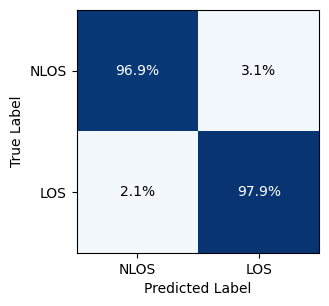

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Example confusion matrix for NLOS/LOS (replace with your actual results)
cm_nlos_los = np.array([
    [5816, 184],   # [True NLOS predicted as NLOS, True NLOS predicted as LOS]
    [86, 3914]    # [True LOS predicted as NLOS, True LOS predicted as LOS]
])
labels = ["NLOS", "LOS"]

def plot_cm_percent_binary(cm, labels, filename):
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
    fig, ax = plt.subplots(figsize=(4, 3))
    im = ax.imshow(cm_percent, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=100)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=0, ha='center')
    ax.set_yticklabels(labels)
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            ax.text(j, i, f"{cm_percent[i, j]:.1f}%",
                    ha="center", va="center",
                    color="white" if cm_percent[i, j] > 50 else "black")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout(pad=0.5)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

plot_cm_percent_binary(cm_nlos_los, labels, "confusion_matrix_mimo_nlos_los_percent.png")

RAY TRACING RESULTS

In [11]:
import onnxruntime as ort  # ONNX Runtime for inference

# best_model_path = os.path.join(nlos_los_save_dir, "best_model_test.onnx")
# /home/l2nguyen/long_nguyen_thesis/model_epoch_36.onnx, best model path here
# best_model_path = "/home/l2nguyen/long_nguyen_thesis/resnet_mimo_nlos_los/20250704-042438/best_model_test.onnx"
# best_model_path = "/home/l2nguyen/long_nguyen_thesis/mimo_nlos_los/20250514-012805/best_model_test.onnx"
best_model_path = "/home/l2nguyen/long_nguyen_thesis/resnet_mimo_nlos_los/20250705-054251/best_model_test.onnx"
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)
# optimizer = tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9)  # SGD with momentum
train_accuracy = SparseCategoricalAccuracy()
val_accuracy = SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()
y_true = []
y_pred = []
y_prob = []
# Optimize dataset loading
# Define training and validation steps with @tf.function for graph execution
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")

@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss
# best_model_path = "/home/l2nguyen/long_nguyen_thesis/model_epoch_36.onnx"

# valid dataset result
y_true = []
y_pred = []
# y_prob = []
for x_val, y_val in test_mimo_ray_tracing_dataset:
    # Convert input to numpy for ONNX Runtime
    x_val_np = x_val.numpy()
    # Run inference using ONNX Runtime
    val_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_val_np})[0]
    val_loss = loss_fn(y_val, val_logits).numpy()
    val_accuracy.update_state(y_val, val_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_val.numpy())
    y_prob.extend(tf.nn.softmax(val_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(val_logits).numpy())
    y_pred.extend(tf.argmax(val_logits, axis=1).numpy()) # if num_classes > 2 else (val_logits > 0.5).astype(int))
val_loss /= len(valid_dataset)
val_acc = val_accuracy.result().numpy()
print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}")
print(f"Metrics for validation dataset")
print(y_true)
print(y_pred)
y_prob = [p[0] for p in y_prob]
print(y_prob)
# check the length of the result

print_metrics(y_true, y_pred, y_prob)

Loading best model from /home/l2nguyen/long_nguyen_thesis/resnet_mimo_nlos_los/20250705-054251/best_model_test.onnx
Validation Loss: 0.0000, Validation Accuracy: 0.5340
Metrics for validation dataset
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

CHANNEL CLASSIFCATION TRAINING

In [39]:
# Example usage:
model = ResNet18(input_shape=(192, 14, 4), num_classes=10, batch_size=16)
model.summary()
writer = tf.summary.create_file_writer(channel_log_dir)
# Define the loss function
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# print the loss function
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)
num_classes = 10
# Define metrics
train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
val_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# Training loop
epochs = 200 # Set the number of epochs
best_loss = float('inf')  # Track the best validation loss
# model.summary()
# train_dataset = train_dataset_siso_channel
# # valid_dataset = valid_dataset_siso_channel
# test_dataset = test_dataset_siso_channel
train_dataset = train_dataset_mimo_channel
# valid_dataset = valid_dataset_mimo_channel
test_dataset = test_dataset_mimo_channel
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss


# Training loop
for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    epoch_loss = 0.0
    train_accuracy.reset_state()

    for x_batch, y_batch in train_dataset:
        loss = train_step(x_batch, y_batch)
        
        epoch_loss += loss.numpy()
    
    epoch_loss /= len(train_dataset)
    train_acc = train_accuracy.result().numpy()

    # Log training metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("training loss", epoch_loss, step=epoch)
        tf.summary.scalar("training accuracy", train_acc, step=epoch)

    print(f"Epoch {epoch + 1} Loss: {epoch_loss:.4f}, Accuracy: {train_acc:.4f}")

    # Validation loop
    test_loss = 0.0
    test_accuracy.reset_state()
    for x_test, y_test in test_dataset:
        loss = test_step(x_test, y_test)
        test_loss += loss.numpy()

    test_loss /= len(test_dataset)
    test_acc = test_accuracy.result().numpy()

    # Log validation metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("test loss", test_loss, step=epoch)
        tf.summary.scalar("test accuracy", test_acc, step=epoch)

    print(f"Validation Loss: {test_loss:.4f}, Accuracy: {test_acc:.4f}")

    # Save the ONNX model at each epoch
    onnx_model_path = os.path.join(channel_save_dir, f"model_epoch_{epoch + 1:02d}.onnx")
    spec = (tf.TensorSpec((None,) + input_shape, tf.float32),)
    onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=spec, opset=11)
    with open(onnx_model_path, "wb") as f:
        f.write(onnx_model.SerializeToString())
    print(f"Model for epoch {epoch + 1} converted to ONNX and saved at {onnx_model_path}")

    # Save the best model based on validation loss
    
    if test_loss < best_loss or epoch == 0:
        best_loss = test_loss
        best_onnx_model_path = os.path.join(channel_save_dir, "best_model.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on test loss")
        patience = 15
    else:
        patience -= 1
        if patience == 0:
            print("Early stopping triggered")
            break
        


Model: "resnet18_custom"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (16, 192, 14, 4)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_204 (Conv2D) │ (16, 96, 7, 16)   │      3,136 │ input_layer_12[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 96, 7, 16)   │         64 │ conv2d_204[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_172 (ReLU)    │ (16, 96, 7, 16)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_24    │ (16, 48, 7, 16)   │          0 │ re_lu_172[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_205 (Conv2D) │ (16, 48, 7, 32)   │      4,608 │ max_pooling2d_24… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_205[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_173 (ReLU)    │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_206 (Conv2D) │ (16, 48, 7, 32)   │      9,216 │ re_lu_173[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_207 (Conv2D) │ (16, 48, 7, 32)   │        512 │ max_pooling2d_24… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_206[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_207[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_64 (Add)        │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_174 (ReLU)    │ (16, 48, 7, 32)   │          0 │ add_64[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_208 (Conv2D) │ (16, 48, 7, 32)   │      9,216 │ re_lu_174[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_208[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_175 (ReLU)    │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_209 (Conv2D) │ (16, 48, 7, 32)   │      9,216 │ re_lu_175[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_209[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_65 (Add)        │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ re_lu_174[0][0] 

 Total params: 2,934,794 (11.20 MB)

 Trainable params: 2,929,962 (11.18 MB)

 Non-trainable params: 4,832 (18.88 KB)

...

Model for epoch 23 converted to ONNX and saved at /home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251/model_epoch_23.onnx
Epoch 24/200
Epoch 24 Loss: 0.3656, Accuracy: 0.8480
Validation Loss: 1.3032, Accuracy: 0.6181


I0000 00:00:1751687685.096683 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751687685.096822 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751687685.098127 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751687685.956031 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751687687.055456 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751687687.055606 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751687687.056822 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 24 converted to ONNX and saved at /home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251/model_epoch_24.onnx
Epoch 25/200
Epoch 25 Loss: 0.3522, Accuracy: 0.8551
Validation Loss: 1.1581, Accuracy: 0.6444


I0000 00:00:1751687713.409880 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751687713.410124 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751687713.411406 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751687714.298305 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751687714.627962 3106851 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751687714.628117 3106851 single_machine.cc:374] Starting new session
I0000 00:00:1751687714.629318 3106851 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 25 converted to ONNX and saved at /home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251/model_epoch_25.onnx
Early stopping triggered


TEST RESULT

dim: 32, h.shape[2]: 14
dim: 64, h.shape[2]: 7
dim: 128, h.shape[2]: 7


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_19 (InputLayer)     │ (16, 192, 14, 4)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_279 (Conv2D)             │ (16, 192, 14, 16)      │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_243 (ReLU)                │ (16, 192, 14, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (16, 96, 7, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_280 (Conv2D)             │ (16, 96, 7, 32)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_244 (ReLU)                │ (16, 96, 7, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_281 (Conv2D)             │ (16, 96, 7, 32)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_245 (ReLU)                │ (16, 96, 7, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_50 (MaxPooling2D) │ (16, 48, 7, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_282 (Conv2D)             │ (16, 48, 7, 64)        │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_246 (ReLU)                │ (16, 48, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_283 (Conv2D)             │ (16, 48, 7, 64)        │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_247 (ReLU)                │ (16, 48, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_284 (Conv2D)             │ (16, 48, 7, 64)        │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_248 (ReLU)                │ (16, 48, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_51 (MaxPooling2D) │ (16, 24, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_285 (Conv2D)             │ (16, 24, 7, 128)       │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_249 (ReLU)                │ (16, 24, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_286 (Conv2D)             │ (16, 24, 7, 128)       │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_250 (ReLU)                │ (16, 24, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_287 (Conv2D)             │ (16, 24, 7, 128)       │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_251 (ReLU)                │ (16, 24, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_52 (MaxPooling2D) │ (16, 12, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (16, 10752)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (16, 1024)             │    11,011,07

 Total params: 12,643,402 (48.23 MB)

 Trainable params: 12,643,402 (48.23 MB)

 Non-trainable params: 0 (0.00 B)

Loading best model from /home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251/best_model.onnx
Test Loss: 0.8280, Test Accuracy: 0.6370


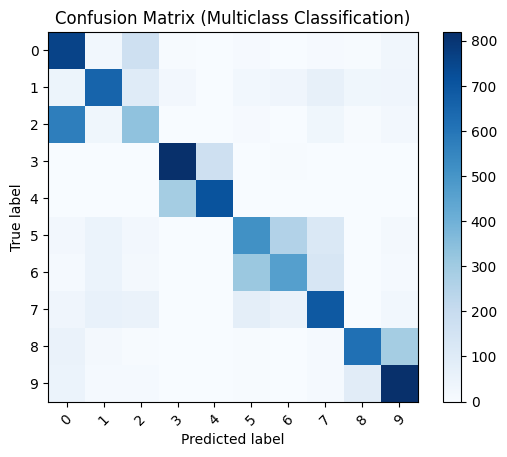

Confusion Matrix:
[[756  24 167   5   1   8   0   8   4  27]
 [ 44 653  97  20   1  25  32  66  30  32]
 [571  29 334   1   0   8   0  31   4  22]
 [  3   2   0 817 172   0   4   0   1   1]
 [  0   0   0 291 708   0   1   0   0   0]
 [ 21  49  22   1   0 514 253 118   3  19]
 [ 11  51  18   3   1 311 463 129   2  11]
 [ 35  59  54   3   1  79  52 689   3  25]
 [ 53  17   6   3   0   4   2  10 617 288]
 [ 50  12  12   1   0   5   0  11  90 819]]
Accuracy: 0.6370
Precision: 0.6441
Recall: 0.6370
F1 Score: 0.6327
ROC AUC: 0.9544
Log Loss: 1.8727


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Train Loss: 0.5869, Train Accuracy: 0.7390
Train Loss: 0.5869, Train Accuracy: 0.7390


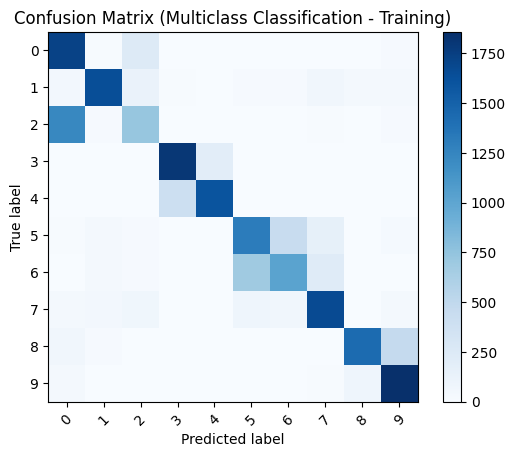

Confusion Matrix:
[[1725   11  242    0    0    1    0    2    3   16]
 [  46 1646  118   13    0   18   19   63   39   38]
 [1226   20  726    0    0    0    0   12    0   16]
 [   0    3    0 1803  193    0    0    0    1    0]
 [   0    0    0  400 1600    0    0    0    0    0]
 [  11   35   21    0    0 1308  436  159    1   29]
 [   6   36   17    1    0  688 1019  222    4    7]
 [  35   46   72    0    0   84   62 1664    2   35]
 [  61   19    6    1    0    4    1    5 1433  470]
 [  38    5    6    1    1    3    0    8   81 1857]]


ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].

In [47]:
n_downsamplings = 3
n_blocks = 0
num_rx_tx = 4  # Number of receive and transmit antennas
input_shape = (192, 14, 4)  # (4, 192, 14)
dim = 16
patience = 10
num_classes = np.unique(train_data_channel_labels).shape[0]
model = VGGNet(
    batch_size=batch_size,
    input_shape=input_shape,
    num_rx_tx=num_rx_tx,
    num_classes=num_classes,
    dim=dim,
    n_downsamplings=n_downsamplings,
    n_blocks=n_blocks,
    norm='instance_norm'
)
model.summary()

# Load the best model
# channel_save_dir = "mimo_models_channel
# channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/mimo_models_channel/20250514-012805"
# channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/siso_nlos_los/20250514-020216"
# channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/mimo_nlos_los/20250514-012805"
# channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/resnet_siso_models_channel/20250705-054529"
# channel_log_dir = "mimo_logs_channel"
channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251"
best_model_path = os.path.join(channel_save_dir, "best_model.onnx")
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")
# train_dataset = train_dataset_siso_channel
# valid_dataset = valid_dataset_siso_channel
# test_dataset = test_dataset_siso_channel
train_dataset = train_dataset_mimo_channel
# valid_dataset = valid_dataset_mimo_channel
test_dataset = test_dataset_mimo_channel

# train_dataset = train_dataset_siso
# test_dataset = test_dataset_siso
# train_dataset = train_dataset_mimo
# test_dataset = test_dataset_mimo
# Evaluate the model
test_loss = 0.0
test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy.reset_state()

y_true = []
y_pred = []
y_prob = []

for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))

    
test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()

print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]

# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    # plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)
else:
    # Multiclass classification
    classes = list(range(num_classes))  # Replace with actual class names if available
    plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
    # plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
    
    # y_prob = [p[1] for p in y_prob]
    # print_metrics(y_true, y_pred, y_prob)
    print_metrics_multiclass(y_true, y_pred, y_prob)
# Training dataset evaluation values
train_loss = 0.0
train_accuracy.reset_state()
y_true = []
y_pred = []
y_prob = []

for x_train, y_train in train_dataset:
    # Convert input to numpy for ONNX Runtime
    x_train_np = x_train.numpy()
    # Run inference using ONNX Runtime
    train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
    train_loss += loss_fn(y_train, train_logits).numpy()
    train_accuracy.update_state(y_train, train_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_train.numpy())
    y_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
    y_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))
train_loss /= len(train_dataset)
train_acc = train_accuracy.result().numpy()
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]
# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    # plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)

# Evaluate the model on the training dataset
train_loss = 0.0
train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
train_accuracy.reset_state()

y_train_true = []
y_train_pred = []
y_train_prob = []

# for x_train, y_train in train_dataset:
#     # Convert input to numpy for ONNX Runtime
#     x_train_np = x_train.numpy()
#     # Run inference using ONNX Runtime
#     train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
#     train_loss += loss_fn(y_train, train_logits).numpy()
#     train_accuracy.update_state(y_train, train_logits)

#     # Collect true labels, predicted labels, and probabilities
#     y_train_true.extend(y_train.numpy())
#     y_train_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
#     y_train_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))

# train_loss /= len(train_dataset)
# train_acc = train_accuracy.result().numpy()

# print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")

# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_train_prob = [p[0] for p in y_train_prob]

# # Visualize training metrics
# if num_classes == 2:
#     # Binary classification
#     plot_confusion_matrix(y_train_true, y_train_pred, title="Confusion Matrix (Binary Classification - Training)")
#     # plot_roc_curve(y_train_true, y_train_prob, title="ROC Curve (Binary Classification - Training)")
#     print_metrics(y_train_true, y_train_pred, y_train_prob)
# else:
#     # Multiclass classification
#     plot_confusion_matrix_multiclass(y_train_true, y_train_pred, classes, title="Confusion Matrix (Multiclass Classification - Training)")
#     # plot_roc_curve_multiclass(y_train_true, np.array(y_train_prob), classes, title="ROC Curve (Multiclass Classification - Training)")
#     # print_metrics_multiclass(y_train_true, y_train_pred, y_train_prob)
#     y_prob = [p[1] for p in y_prob]
#     print_metrics(y_true, y_pred, y_prob)


In [48]:
import numpy as np
import matplotlib.pyplot as plt

cm_mimo_new = np.array([
    [756, 24, 167, 5, 1, 8, 0, 8, 4, 27],
    [44, 653, 97, 20, 1, 25, 32, 66, 30, 32],
    [571, 29, 334, 1, 0, 8, 0, 31, 4, 22],
    [3, 2, 0, 817, 172, 0, 4, 0, 1, 1],
    [0, 0, 0, 291, 708, 0, 1, 0, 0, 0],
    [21, 49, 22, 1, 0, 514, 253, 118, 3, 19],
    [11, 51, 18, 3, 1, 311, 463, 129, 2, 11],
    [35, 59, 54, 3, 1, 79, 52, 689, 3, 25],
    [53, 17, 6, 3, 0, 4, 2, 10, 617, 288],
    [50, 12, 12, 1, 0, 5, 0, 11, 90, 819]
])

labels = [
    r"TDL $\mathsf{A}$", r"TDL $\mathsf{B}$", r"TDL $\mathsf{C}$", r"TDL $\mathsf{D}$", r"TDL $\mathsf{E}$",
    r"CDL $\mathsf{A}$", r"CDL $\mathsf{B}$", r"CDL $\mathsf{C}$", r"CDL $\mathsf{D}$", r"CDL $\mathsf{E}$"
]

def plot_cm_percent(cm, labels, filename):
    cm_percent = cm / 1000 * 100  # 1000 samples per class
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm_percent, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticklabels(labels)
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            ax.text(j, i, f"{cm_percent[i, j]:.1f}%",
                    ha="center", va="center",
                    color="white" if cm_percent[i, j] > cm_percent.max() / 2 else "black")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout(pad=0.5)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

plot_cm_percent(cm_mimo_new, labels, "confusion_matrix_mimo_channel_resnet_new_percent.png")

SISO CHANNEL


In [ ]:
# from keras import regularizers
# def VGGNet(input_shape=(192, 14, 4),
#            output_channels=4,
#            dim=4,
#            n_downsamplings=1,
#            n_blocks=1,
#            num_classes=2,
#            num_rx_tx=4,
#            batch_size=1,
#            norm='instance_norm'):
#     def _residual_block(h):
#         dim = h.shape[-1]
#         h = h
#         h = keras.layers.Conv2D(dim, 1, strides=1, padding='same', dilation_rate=1, use_bias=False)(h)
#         h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        
#         return keras.layers.add([h, h])

#     # 0: Input
#     h = inputs = keras.Input(shape=input_shape, batch_size=batch_size)
#     # take the final dimension for the output
#     last_dim = inputs.shape[-1]
#     temp_dim = None
#     odd = True
    
#     # 1: First convolution, for the first layer
#     h = keras.layers.Conv2D(dim, 1, strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
#     h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
#     # h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
#     # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    
#     # # 2: Upsampling layers (controlled by n_downsamplings)
#     for i in range(n_downsamplings):
#         dim *= 2
#         # check if the second dimension is odd or even
#         print(f"dim: {dim}, h.shape[2]: {h.shape[2]}")

#         if h.shape[2] % 2 != 0 and odd == True:
#                 temp_dim = (dim // 2) // 2
#                 odd = False
#         if h.shape[2] % 2 == 0:
#             # h = keras.layers.Conv2D(dim, (1, 1), strides=(2, 2), padding='same', dilation_rate=1, use_bias=False)(h)
#             h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same')(h)
#             # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
#         else:
#             # h = keras.layers.Conv2D(dim, (1, 1), strides=(2, 1), padding='same', dilation_rate=1, use_bias=False)(h)
#             h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 1), padding='same')(h)
#             # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
#         if i <=0:
#             value = 2
#         else:
#             value = 3
#         for j in range(min(value, 3)):
#             h = keras.layers.Conv2D(dim, 1, strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
#             h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
#     # 3: Residual Block
#     for _ in range(n_blocks):
#         h = _residual_block(h)


#     if h.shape[2] % 2 == 0:
#         h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same')(h)
#     else:
#         h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 1), padding='same')(h)
#     # 4: Upsampling layers (controlled by n_downsamplings
#     # Add classification head
#     # Add classification head with L2 regularization and Dropout
#     h = tf.keras.layers.Flatten()(h)
#     h = tf.keras.layers.Dense(1024, activation='relu',
#                             kernel_regularizer=regularizers.l2(5e-4))(h)
#     h = tf.keras.layers.Dense(1024, activation='relu',
#                             kernel_regularizer=regularizers.l2(5e-4))(h)
#     h = tf.keras.layers.Dropout(0.5)(h)
#     h = tf.keras.layers.Dense(512, activation='relu',
#                             kernel_regularizer=regularizers.l2(5e-4))(h)
#     h = tf.keras.layers.Dropout(0.5)(h)
    
#     # use without regularization
#     # h = tf.keras.layers.Dense(1024, activation='relu')(h)
#     # h = tf.keras.layers.Dense(512, activation='relu')(h)
#     # h = tf.keras.layers.Flatten()(h)
#     # h = tf.keras.layers.Dense(1024, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(h)
#     # h = tf.keras.layers.Dense(1024, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(h)
#     # use global average pooling
#     # h = tf.keras.layers.GlobalAveragePooling2D()(h)
#     # h = tf.keras.layers.Dropout(0.5)(h)
#     output = tf.keras.layers.Dense(num_classes, activation='softmax')(h)
    
#     # output = tf.keras.layers.Dense(num_classes, activation='softmax')(h)
#     model = tf.keras.Model(inputs=inputs, outputs=output)
#     return model


# n_downsamplings = 3
# n_blocks = 0
# num_rx_tx = 4  # Number of receive and transmit antennas
# input_shape = (192, 14, 4)  # (4, 192, 14)
# dim = 16
# patience = 10
# num_classes = np.unique(train_data_channel_labels).shape[0]
# model = VGGNet(
#     batch_size=batch_size,
#     input_shape=input_shape,
#     num_rx_tx=num_rx_tx,
#     num_classes=num_classes,
#     dim=dim,
#     n_downsamplings=n_downsamplings,
#     n_blocks=n_blocks,
#     norm='instance_norm'
# )
# model.summary()

# # Load the best model
# # channel_save_dir = "mimo_models_channel
# # channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/siso_models_channel/20250514-020216"
# # channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/mimo_models_channel/20250514-012805"
# channel_save_dir ="/home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250704-140127"
# best_model_path = os.path.join(channel_save_dir, "best_model.onnx")
# if os.path.exists(best_model_path):
#     print(f"Loading best model from {best_model_path}")
#     # Use ONNX Runtime to load the ONNX model
#     ort_session = ort.InferenceSession(best_model_path)
# else:
#     raise FileNotFoundError(f"Best model not found at {best_model_path}")
# train_dataset = train_dataset_siso_channel
# # valid_dataset = valid_dataset_siso_channel
# test_dataset = test_dataset_siso_channel
# train_dataset = train_dataset_mimo_channel
# # valid_dataset = valid_dataset_mimo_channel
# test_dataset = test_dataset_mimo_channel
# # Evaluate the model
# test_loss = 0.0
# test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# test_accuracy.reset_state()

# y_true = []
# y_pred = []
# y_prob = []

# for x_test, y_test in test_dataset:
#     # Convert input to numpy for ONNX Runtime
#     x_test_np = x_test.numpy()
#     # Run inference using ONNX Runtime
#     test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
#     test_loss += loss_fn(y_test, test_logits).numpy()
#     test_accuracy.update_state(y_test, test_logits)

#     # Collect true labels, predicted labels, and probabilities
#     y_true.extend(y_test.numpy())
#     y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
#     y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))

    
# test_loss /= len(test_dataset)
# test_acc = test_accuracy.result().numpy()

# print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob = [p[0] for p in y_prob]

# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
#     plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true, y_pred, y_prob)
# else:
#     # Multiclass classification
#     classes = list(range(num_classes))  # Replace with actual class names if available
#     plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
#     plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
#     print_metrics_multiclass(y_true, y_pred, y_prob)
    
# # Training dataset evaluation values
# train_loss = 0.0
# train_accuracy.reset_state()
# y_true = []
# y_pred = []
# y_prob = []

# for x_train, y_train in train_dataset:
#     # Convert input to numpy for ONNX Runtime
#     x_train_np = x_train.numpy()
#     # Run inference using ONNX Runtime
#     train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
#     train_loss += loss_fn(y_train, train_logits).numpy()
#     train_accuracy.update_state(y_train, train_logits)

#     # Collect true labels, predicted labels, and probabilities
#     y_true.extend(y_train.numpy())
#     y_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
#     y_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))
# train_loss /= len(train_dataset)
# train_acc = train_accuracy.result().numpy()
# print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob = [p[0] for p in y_prob]
# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
#     plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true, y_pred, y_prob)

# # Evaluate the model on the training dataset
# train_loss = 0.0
# train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# train_accuracy.reset_state()

# y_train_true = []
# y_train_pred = []
# y_train_prob = []

# for x_train, y_train in train_dataset:
#     # Convert input to numpy for ONNX Runtime
#     x_train_np = x_train.numpy()
#     # Run inference using ONNX Runtime
#     train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
#     train_loss += loss_fn(y_train, train_logits).numpy()
#     train_accuracy.update_state(y_train, train_logits)

#     # Collect true labels, predicted labels, and probabilities
#     y_train_true.extend(y_train.numpy())
#     y_train_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
#     y_train_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))

# train_loss /= len(train_dataset)
# train_acc = train_accuracy.result().numpy()

# print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")

# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_train_prob = [p[0] for p in y_train_prob]

# # Visualize training metrics
# if num_classes == 2:
#     # Binary classification
#     plot_confusion_matrix(y_train_true, y_train_pred, title="Confusion Matrix (Binary Classification - Training)")
#     plot_roc_curve(y_train_true, y_train_prob, title="ROC Curve (Binary Classification - Training)")
#     print_metrics(y_train_true, y_train_pred, y_train_prob)
# else:
#     # Multiclass classification
#     plot_confusion_matrix_multiclass(y_train_true, y_train_pred, classes, title="Confusion Matrix (Multiclass Classification - Training)")
#     plot_roc_curve_multiclass(y_train_true, np.array(y_train_prob), classes, title="ROC Curve (Multiclass Classification - Training)")
#     print_metrics_multiclass(y_train_true, y_train_pred, y_train_prob)


dim: 32, h.shape[2]: 14
dim: 64, h.shape[2]: 7
dim: 128, h.shape[2]: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (16, 192, 14, 4)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (16, 192, 14, 16)      │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_17 (ReLU)                 │ (16, 192, 14, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (16, 96, 7, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (16, 96, 7, 32)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_18 (ReLU)                 │ (16, 96, 7, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (16, 96, 7, 32)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_19 (ReLU)                 │ (16, 96, 7, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (16, 48, 7, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (16, 48, 7, 64)        │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_20 (ReLU)                 │ (16, 48, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (16, 48, 7, 64)        │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_21 (ReLU)                 │ (16, 48, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (16, 48, 7, 64)        │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_22 (ReLU)                 │ (16, 48, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (16, 24, 7, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (16, 24, 7, 128)       │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_23 (ReLU)                 │ (16, 24, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (16, 24, 7, 128)       │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_24 (ReLU)                 │ (16, 24, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (16, 24, 7, 128)       │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_25 (ReLU)                 │ (16, 24, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (16, 12, 7, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (16, 10752)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (16, 1024)             │    11,011,07

 Total params: 12,643,402 (48.23 MB)

 Trainable params: 12,643,402 (48.23 MB)

 Non-trainable params: 0 (0.00 B)

FileNotFoundError: Best model not found at /home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250704-140127/best_model.onnx

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

cm_mimo = np.array([
    [553, 29, 333, 6, 1, 16, 0, 7, 31, 24],
    [32, 693, 72, 21, 6, 56, 36, 30, 39, 15],
    [326, 53, 521, 1, 0, 19, 3, 23, 32, 22],
    [4, 3, 0, 735, 254, 0, 2, 1, 0, 1],
    [0, 0, 0, 192, 808, 0, 0, 0, 0, 0],
    [16, 63, 13, 2, 2, 566, 278, 33, 8, 19],
    [14, 73, 10, 4, 1, 307, 545, 32, 4, 10],
    [15, 72, 32, 8, 5, 100, 136, 590, 11, 31],
    [42, 32, 19, 8, 2, 8, 1, 0, 716, 172],
    [31, 16, 28, 1, 4, 6, 0, 4, 217, 693]
])

labels = [
    r"TDL $\mathsf{A}$", r"TDL $\mathsf{B}$", r"TDL $\mathsf{C}$", r"TDL $\mathsf{D}$", r"TDL $\mathsf{E}$",
    r"CDL $\mathsf{A}$", r"CDL $\mathsf{B}$", r"CDL $\mathsf{C}$", r"CDL $\mathsf{D}$", r"CDL $\mathsf{E}$"
]

def plot_cm_percent(cm, labels, filename):
    cm_percent = cm / 1000 * 100  # 1000 samples per class
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm_percent, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticklabels(labels)
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            ax.text(j, i, f"{cm_percent[i, j]:.1f}%",
                    ha="center", va="center",
                    color="white" if cm_percent[i, j] > cm_percent.max() / 2 else "black")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout(pad=0.5)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

plot_cm_percent(cm_mimo, labels, "confusion_matrix_mimo_channel_resnet_new_percent.png")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# MIMO confusion matrix
cm_mimo = np.array([
    [757, 22, 163, 15, 5, 6, 1, 8, 16, 7],
    [55, 765, 70, 16, 1, 20, 23, 16, 26, 8],
    [519, 47, 393, 5, 0, 2, 0, 16, 8, 10],
    [35, 8, 8, 756, 191, 2, 0, 0, 0, 0],
    [8, 1, 1, 153, 835, 2, 0, 0, 0, 0],
    [12, 88, 17, 5, 1, 406, 388, 67, 4, 12],
    [3, 84, 15, 0, 0, 276, 526, 91, 3, 2],
    [23, 85, 37, 2, 3, 77, 121, 635, 4, 13],
    [20, 41, 6, 1, 0, 12, 1, 6, 803, 110],
    [12, 24, 15, 0, 0, 9, 1, 12, 106, 821]
])

# SISO confusion matrix
cm_siso = np.array([
    [714, 13, 265, 0, 0, 0, 0, 4, 2, 2],
    [40, 813, 28, 35, 5, 3, 28, 4, 24, 20],
    [191, 17, 784, 0, 0, 1, 0, 5, 0, 2],
    [3, 13, 0, 885, 74, 0, 2, 1, 16, 6],
    [1, 7, 0, 83, 858, 0, 1, 0, 0, 50],
    [1, 12, 1, 0, 0, 551, 359, 66, 1, 9],
    [2, 15, 2, 0, 0, 231, 696, 40, 3, 11],
    [0, 0, 1, 0, 0, 63, 31, 883, 5, 17],
    [3, 18, 1, 31, 4, 0, 5, 6, 907, 25],
    [4, 25, 1, 12, 36, 4, 17, 38, 16, 847]
])

labels = [
    r"TDL $\mathsf{A}$", r"TDL $\mathsf{B}$", r"TDL $\mathsf{C}$", r"TDL $\mathsf{D}$", r"TDL $\mathsf{E}$",
    r"CDL $\mathsf{A}$", r"CDL $\mathsf{B}$", r"CDL $\mathsf{C}$", r"CDL $\mathsf{D}$", r"CDL $\mathsf{E}$"
]

def plot_cm_percent(cm, labels, filename):
    cm_percent = cm / 1000 * 100  # 1000 samples per class
    fig, ax = plt.subplots(figsize=(6, 5))  # Smaller figure size
    im = ax.imshow(cm_percent, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticklabels(labels)
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            ax.text(j, i, f"{cm_percent[i, j]:.1f}%",
                    ha="center", va="center",
                    color="white" if cm_percent[i, j] > cm_percent.max() / 2 else "black")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout(pad=0.5)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

plot_cm_percent(cm_mimo, labels, "confusion_matrix_mimo_percent.png")
plot_cm_percent(cm_siso, labels, "confusion_matrix_siso_percent.png")

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# # Example confusion matrices (replace with your actual results)
# cm_siso = np.array([
#     [5577, 423],
#     [263, 3737]
# ])
# cm_mimo = np.array([
#     [5632, 368],
#     [211, 3789]
# ])

# labels = ["NLOS", "LOS"]

# def plot_cm_percent_binary(cm, labels, filename):
#     cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
#     fig, ax = plt.subplots(figsize=(4, 3))
#     im = ax.imshow(cm_percent, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=100)
#     ax.set_xticks(np.arange(len(labels)))
#     ax.set_yticks(np.arange(len(labels)))
#     ax.set_xticklabels(labels, rotation=0, ha='center')
#     ax.set_yticklabels(labels)
#     for i in range(cm_percent.shape[0]):
#         for j in range(cm_percent.shape[1]):
#             ax.text(j, i, f"{cm_percent[i, j]:.1f}%",
#                     ha="center", va="center",
#                     color="white" if cm_percent[i, j] > 50 else "black")
#     ax.set_xlabel('Predicted Label')
#     ax.set_ylabel('True Label')
#     plt.tight_layout(pad=0.5)
#     plt.savefig(filename, dpi=300, bbox_inches='tight')
#     plt.show()
#     plt.close()

# plot_cm_percent_binary(cm_siso, labels, "confusion_matrix_siso_nlos_los_percent.png")
# plot_cm_percent_binary(cm_mimo, labels, "confusion_matrix_mimo_nlos_los_percent.png")

SNR DEPENDENT CHANNEL

Loading best model from /home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251/best_model.onnx
Test dataset 0db shape: (None, 192, 14, 4) (None,)
Test Loss: 3.5631, Test Accuracy: 0.6191
Metrics for 0db
Accuracy: 0.4335
Precision: 0.4374
Recall: 0.4335
F1 Score: 0.4247
ROC AUC: 0.8801
Log Loss: 2.0536


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 5db
Accuracy: 0.6166
Precision: 0.6143
Recall: 0.6166
F1 Score: 0.6089
ROC AUC: 0.9440
Log Loss: 1.8859


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 10db
Accuracy: 0.6943
Precision: 0.6986
Recall: 0.6943
F1 Score: 0.6859
ROC AUC: 0.9640
Log Loss: 1.8044


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 15db
Accuracy: 0.7248
Precision: 0.7302
Recall: 0.7248
F1 Score: 0.7173
ROC AUC: 0.9699
Log Loss: 1.7741
Test Loss: 1360.9625, Test Accuracy: 0.6191


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Test Loss: 0.8774, Test Accuracy: 0.6215


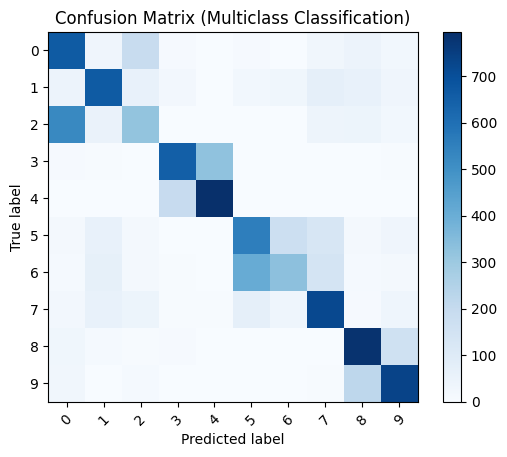

Confusion Matrix:
[[664  33 190   9   3   9   0  25  45  22]
 [ 45 664  56  19   3  23  29  70  59  32]
 [523  51 317   3   0   2   0  40  41  23]
 [  7   6   1 652 325   2   1   0   2   4]
 [  2   3   2 195 795   1   0   0   0   2]
 [ 18  61  15   0   1 554 173 128  17  33]
 [ 11  67  15   4   0 404 331 140  10  18]
 [ 19  58  41   5   4  71  37 720   8  37]
 [ 31  10   6   7   0   0   0   2 785 159]
 [ 27   3  12   1   0   1   0   5 218 733]]
Accuracy: 0.6215
Precision: 0.6191
Recall: 0.6215
F1 Score: 0.6125
ROC AUC: 0.9485
Log Loss: 1.8761


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [38]:
channel_save_dir = "/home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251" 

# onnx model path
best_model_path = os.path.join(channel_save_dir, "best_model.onnx")
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")
y_true = []
y_pred = []
y_prob = []
print(f"Test dataset 0db shape:", test_dataset_0db_mimo.element_spec[0].shape, test_dataset_0db_mimo.element_spec[1].shape)
# for x_test, y_test in test_dataset_0db_mimo:
for x_test, y_test in test_dataset_0db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(f"Metrics for 0db")
# y_prob = [p[0] for p in y_prob]
# print(y_true)
# print(y_pred)
# print(y_prob)
# print_metrics(y_true, y_pred, y_prob)
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_5db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 5db")
# print(y_true)
# print(y_pred)
# print(y_prob)
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_10db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 10db")
# y_prob = [p[0] for p in y_prob]
# print_metrics(y_true, y_pred, y_prob)
print_metrics_multiclass(y_true, y_pred, y_prob)
y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_15db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

# y_prob = [p[0] for p in y_prob]
print(f"Metrics for 15db")
print_metrics_multiclass(y_true, y_pred, y_prob)


print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

train_dataset = train_dataset_mimo_channel
# valid_dataset = valid_dataset_mimo_channel
test_dataset = test_dataset_mimo_channel

# Evaluate the model
test_loss = 0.0
test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy.reset_state()
y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))
test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]
# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    # plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)
else:
    # Multiclass classification
    classes = list(range(num_classes))  # Replace with actual class names if available
    plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
    # plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
    print_metrics_multiclass(y_true, y_pred, y_prob)
    

In [40]:
import onnxruntime as ort
import numpy as np
import os

# Set up test dataset (already batched)
test_dataset = test_dataset_mimo_channel  # or test_dataset_siso_channel

# Path to the best ONNX model
best_model_path = os.path.join(channel_save_dir, "best_model.onnx")
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Best model not found at {best_model_path}")
print(f"Loading best model from {best_model_path}")
ort_session = ort.InferenceSession(best_model_path)

# Define the loss function and metric
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
test_accuracy = tf.keras.metrics.SparseCategoricalAccuracy()
test_accuracy.reset_state()

# Evaluation loop
test_loss = 0.0
y_true = []
y_pred = []
y_prob = []

for x_test, y_test in test_dataset:
    x_test_np = x_test.numpy()
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))
    # print(test_logits)
    # print(test_loss)
    
test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# For binary classification, flatten probabilities
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]

# Print metrics (choose the right function for your task)
if num_classes == 2:
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)
else:
    # classes = list(range(num_classes))
    # plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
    # plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
    print_metrics_multiclass(y_true, y_pred, y_prob)
    
for x_test, y_test in test_dataset_0db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(f"Metrics for 0db")
# y_prob = [p[0] for p in y_prob]
# print(y_true)
# print(y_pred)
# print(y_prob)
# print_metrics(y_true, y_pred, y_prob)
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_5db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 5db")
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_10db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 10db")
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
for x_test, y_test in test_dataset_15db_mimo_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 15db")
print_metrics_multiclass(y_true, y_pred, y_prob)


print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(num_classes)

# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob = [p[0] for p in y_prob]

# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     # plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
#     # plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true, y_pred, y_prob)
# else:
#     # Multiclass classification
#     # classes = list(range(num_classes))  # Replace with actual class names if available
#     # plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
#     # plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
#     print_metrics_multiclass(y_true, y_pred, y_prob, classes)
    
# # training dataset evaluation metrics result
# train_loss = 0.0
# train_accuracy.reset_state()
# y_true_train = []
# y_pred_train = []
# y_prob_train = []
# for x_train, y_train in train_dataset:
#     # Convert input to numpy for ONNX Runtime
#     x_train_np = x_train.numpy()
#     # Run inference using ONNX Runtime
#     train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
#     train_loss += loss_fn(y_train, train_logits).numpy()
#     train_accuracy.update_state(y_train, train_logits)

#     # Collect true labels, predicted labels, and probabilities
#     y_true_train.extend(y_train.numpy())
#     y_prob_train.extend(tf.nn.softmax(train_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
#     y_pred_train.extend(tf.argmax(train_logits, axis=1).numpy()) # if num_classes > 2 else (train_logits > 0.5).astype(int))
# train_loss /= len(train_dataset)
# train_acc = train_accuracy.result().numpy()
# print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob_train = [p[0] for p in y_prob_train]
# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     # plot_confusion_matrix(y_true_train, y_pred_train, title="Confusion Matrix (Binary Classification)")
#     # plot_roc_curve(y_true_train, y_prob_train, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true_train, y_pred_train, y_prob_train)

Loading best model from /home/l2nguyen/long_nguyen_thesis/resnet_mimo_models_channel/20250705-054251/best_model.onnx
Test Loss: 0.8280, Test Accuracy: 0.6370
Accuracy: 0.6370
Precision: 0.6441
Recall: 0.6370
F1 Score: 0.6327
ROC AUC: 0.9544
Log Loss: 1.8727


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Test Loss: 1.3182, Test Accuracy: 0.5372
Metrics for 0db
Accuracy: 0.5372
Precision: 0.5499
Recall: 0.5372
F1 Score: 0.5336
ROC AUC: 0.9274
Log Loss: 1.9618


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 5db
Accuracy: 0.6250
Precision: 0.6335
Recall: 0.6250
F1 Score: 0.6181
ROC AUC: 0.9510
Log Loss: 1.8848


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 10db
Accuracy: 0.7160
Precision: 0.7252
Recall: 0.7160
F1 Score: 0.7097
ROC AUC: 0.9690
Log Loss: 1.8004


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 15db
Accuracy: 0.7454
Precision: 0.7548
Recall: 0.7454
F1 Score: 0.7408
ROC AUC: 0.9738
Log Loss: 1.7710
Test Loss: 1288.2825, Test Accuracy: 0.5372
10


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
